<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/OT-day4/OT_Day4_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ONNX·TensorRT Day 4 — TensorRT 첫걸음: ONNX 를 엔진으로 바꾸기

**온디바이스 AI · ONNX·TensorRT 4/5 · 11/9(월)** · Google Colab (**T4 GPU 런타임 필수**) · TensorRT 10.16.1.11 · Polygraphy · ONNX Runtime

어제 profiling 에서 MobileNetV3 시간의 절반 이상이 **Conv** 였습니다. 오늘은 같은 `mnv3s` 를 **TensorRT 엔진** — 이 GPU 전용으로 다시 조립한 완성품 — 으로 바꾸고, **FP16** 으로 한 번 더 빠르게 만듭니다.

> 오늘은 **같은 일을 두 번** 합니다. 먼저 **명령 한 줄** (Polygraphy) 로 쉽게 → 다음엔 **Python 코드**로 한 단계씩. 명령이 안에서 하던 일을 코드로 다시 보면 엔진이 무엇인지 보입니다.

오늘의 목표

1. ONNX · ONNX Runtime · TensorRT 엔진의 차이를 설명하고, 엔진이 **이 GPU · 이 TensorRT 버전 전용**인 이유를 말한다.
2. `polygraphy convert` 로 엔진을 만들고, `polygraphy run` 으로 ONNX Runtime 과 결과를 비교한다 (PASSED / FAILED · atol).
3. Python API 로 엔진을 **빌드** (Logger → Builder → Network → Parser → Config → 저장) 하고 `build_engine()` 으로 묶는다.
4. Python API 로 엔진을 **실행** (Runtime → Context → 이름 · shape → GPU 버퍼 → 실행) 하고 `trt_runner()` 로 묶는다.
5. **FP16** 의 표현 범위 · 정밀도를 이해하고, 속도와 정확도를 함께 비교한다.
6. 엔진 레이어를 들여다보고 **왜 빨라졌는지** (레이어 합치기) 설명한다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 3 복습 퀴즈 · TensorRT 란 · 설치 확인 · 고정 크기 ONNX |
| 2 | 10:00–10:50 | 명령 한 줄로 엔진 만들기 — `polygraphy convert` |
| 3 | 11:00–11:50 | 명령 한 줄로 비교하기 — `polygraphy run --onnxrt --trt` |
| 4 | 13:00–13:50 | Python 으로 엔진 빌드 → `build_engine()` |
| 5 | 14:00–14:50 | Python 으로 엔진 실행 → `trt_runner()` |
| 6 | 15:00–15:50 | FP16 으로 더 빠르게 — 속도 · 정확도 |
| 7 | 16:00–16:50 | 왜 빨라졌나 — 엔진 레이어 들여다보기 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 실행기 4가지 성능표 · 채점 |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → **T4 GPU*** 를 **반드시** 고르세요. 오늘은 GPU 없이는 진행할 수 없습니다.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다. 막히면 **🔒 정답 보기**.
3. **엔진 빌드는 오래 걸립니다** (mnv3s 기준 수십 초~1분 남짓). 빌드 셀을 실행하고 기다리는 동안 설명을 읽으세요. 두 번 누르지 마세요.
4. 시간 숫자 · 빌드 시간 · 레이어 수는 Colab 장비와 버전마다 다릅니다. 확인 셀은 값이 아니라 **방법**을 검사합니다.
5. 8교시 미니 프로젝트는 이 노트북 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출하고, **`ot_baseline.csv` 를 Drive 에 저장**하세요.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/OT_Day4.pdf](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/OT_Day4.pdf) |

**오늘의 모델** — Day 3 와 같은 **MobileNetV3-Small** (구조만, BN 통계 seed 고정) 과 학습된 **SimpleConvNet** (MNIST, 정확도 확인용). 단, 오늘은 **배치 1 로 고정된** ONNX 를 씁니다 (1-2 에서 이유).

In [ ]:
# ▶ 설치 셀 — TensorRT · Polygraphy · GPU 판 ONNX Runtime. 처음 한 번, 2~3분
# TensorRT 는 10.16.1.11 로 고정: 11.x 부터는 '빌드 옵션 한 줄로 FP16' (BuilderFlag.FP16) 이 없어져 오늘 6교시 방식이 바뀝니다
%pip uninstall -y -q onnxruntime
%pip install -q onnx onnxscript onnxruntime-gpu "tensorrt-cu12==10.16.1.11" polygraphy

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, re, time, json, inspect, warnings, collections, subprocess, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import onnx
import onnxruntime as ort
import tensorrt as trt

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 3)
torch.manual_seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/OT-day4"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
CUDA = ["CUDAExecutionProvider", "CPUExecutionProvider"]
try:
    ort.preload_dlls()
except Exception:
    pass
GPU_OK = torch.cuda.is_available()

def fetch(name):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

class SimpleConvNet(nn.Module):              # VB Day 1 · OT Day 1~3
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 30, 5)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(30 * 12 * 12, 100)
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def make_mnv3s():                            # Day 3 와 같은 모델
    torch.manual_seed(0)
    m = torchvision.models.mobilenet_v3_small(weights=None)
    with torch.no_grad():
        for b in m.modules():
            if isinstance(b, nn.BatchNorm2d):
                b.running_mean.uniform_(-0.1, 0.1); b.running_var.uniform_(0.5, 1.5)
    return m.eval()

def bench(sess, x, n=100, warm=10):          # Day 3 2-3 — ONNX Runtime 세션용
    name = sess.get_inputs()[0].name
    return bench_fn(lambda: sess.run(None, {name: x}), n, warm, x.shape[0])

def bench_fn(fn, n=100, warm=10, batch=1):   # 오늘 — 무엇이든 '한 번 실행하는 함수' 를 잰다
    for _ in range(warm):
        fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean": t.mean(), "p50": np.percentile(t, 50), "p95": np.percentile(t, 95), "fps": 1000 / t.mean() * batch}

def sh(cmd, log=None, tail=12):
    """터미널 명령 실행 → 마지막 몇 줄만 보여 주고, 전체는 log 파일로"""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = r.stdout + r.stderr
    if log:
        open(log, "w").write(out)
    print("\n".join(out.strip().splitlines()[-tail:]))
    return r.returncode

print("PyTorch", torch.__version__, "| ONNX Runtime", ort.__version__, "| TensorRT", trt.__version__)
print("GPU:", torch.cuda.get_device_name(0) if GPU_OK else "없음 ⚠️ — 런타임 유형을 T4 GPU 로 바꾸고 설치 셀부터 다시")

## 1교시 — Day 3 복습 · TensorRT 란 · 설치 확인

| 시간 | 할 일 |
|---|---|
| 09:00–09:15 | **Day 3 복습 퀴즈 20문항** (Google Forms — 강사가 링크 공유) |
| 09:15–09:30 | TensorRT 란 — 설계도 · 기계 · 완성품 |
| 09:30–09:50 | 문제 1-1 · 1-2 — 버전 · GPU 확인, 고정 크기 ONNX 만들기 |

> 🎬 **애니메이션** [D4-1 설계도 · 기계 · 완성품](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

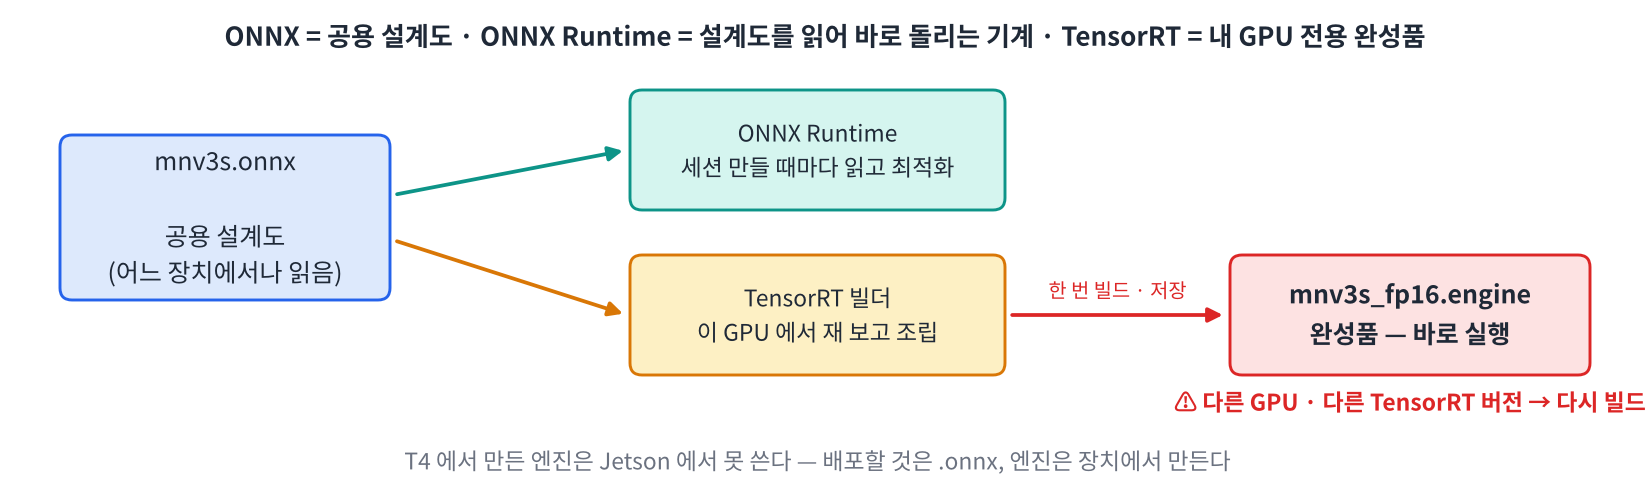

In [ ]:
#@title 🖼 그림 — ONNX · ONNX Runtime · TensorRT
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f1_analogy.png", embed=True, width=880))

| | ONNX Runtime (Day 3) | TensorRT (오늘) |
|---|---|---|
| 입력 | `.onnx` | `.onnx` |
| 언제 최적화? | **세션 만들 때마다** (1초 이내) | **빌드할 때 한 번** (수십 초~분) — 결과를 `.engine` 으로 저장 |
| 어떻게? | 정해진 규칙으로 노드 합치기 | 규칙 + **이 GPU 에서 커널 후보를 직접 재 보고** 가장 빠른 것 선택 |
| 어디서? | CPU · GPU · 여러 장치 | **NVIDIA GPU 전용** (Jetson 포함) |
| 결과 파일 | 없음 (메모리 안) | `.engine` — **만든 GPU 종류 · TensorRT 버전에서만** 동작 |

**문제 1-1** **설치 확인** — TensorRT 버전과 GPU 를 확인하세요. TensorRT 엔진은 GPU 의 **compute capability** (세대 번호) 마다 다르게 만들어집니다. T4 는 7.5, Jetson Orin 은 8.7 입니다.

In [ ]:
print("TensorRT 버전:", trt.____)
print("GPU 이름:", torch.cuda.get_device_name(0))
cc = torch.cuda.get_device_capability(0)
print("compute capability:", cc, "→", f"sm_{cc[0]}{cc[1]}")

In [ ]:
assert GPU_OK and trt.__version__.startswith("10.") and len(cc) == 2
print("✅ TensorRT", trt.__version__, "· GPU", torch.cuda.get_device_name(0), "— 오늘 준비 완료")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACnByaW50KCJUZW5zb3JSVCDrsoTsoIQ6IiwgdHJ0Ll9fdmVyc2lvbl9f"
    "KQpwcmludCgiR1BVIOydtOumhDoiLCB0b3JjaC5jdWRhLmdldF9kZXZpY2VfbmFtZSgwKSkKY2MgPSB0b3JjaC5j"
    "dWRhLmdldF9kZXZpY2VfY2FwYWJpbGl0eSgwKQpwcmludCgiY29tcHV0ZSBjYXBhYmlsaXR5OiIsIGNjLCAi4oaS"
    "IiwgZiJzbV97Y2NbMF19e2NjWzFdfSIpCgrwn5KhIO2VtOyEpApUNCA9ICg3LCA1KSDihpIgc21fNzUuIOydtCDs"
    "iKvsnpDqsIAg64uk66W4IEdQVSAo7JiIOiBKZXRzb24gT3JpbiA4LjcpIOyXkOyEnOuKlCDsl5Tsp4TsnYQg64uk"
    "7IucIOu5jOuTnO2VtOyVvCDtlanri4jri6QuClRlbnNvclJUIOuyhOyghOydtCAxMC54IOqwgCDslYTri4jrqbQg"
    "7ISk7LmYIOyFgOydhCDqsbTrhIjrm7Qg6rKDIOKAlCDshKTsuZgg7IWA67aA7YSwIOuLpOyLnC4="
).decode("utf-8"))

**문제 1-2** **고정 크기 ONNX** — TensorRT 는 입력 크기가 정해져 있으면 그 크기에 딱 맞는 커널을 고릅니다. 배치를 자유롭게 하면 '최소 · 최적 · 최대 크기' 설정 (optimization profile) 이 따로 필요해서, 오늘은 **배치 1 로 고정**합니다. `dynamic_axes` **없이** 내보내세요.

In [ ]:
mnv3s = make_mnv3s()
torch.onnx.export(mnv3s, torch.randn(1, 3, 224, 224), "mnv3s_b1.onnx", input_names=["input"], output_names=["logits"],
                  opset_version=17, **EXPORT_KW)                          # dynamic_axes 없음 → 배치 1 고정
cnn = SimpleConvNet().eval()
cnn.load_state_dict(torch.load(fetch("mnist_cnn.pt"), map_location="cpu"))
torch.onnx.export(cnn, torch.zeros(1, 1, 28, 28), "mnist_cnn_b1.onnx", input_names=["input"], output_names=["logits"],
                  opset_version=17, **EXPORT_KW)

x1 = np.random.rand(1, 3, 224, 224).astype(np.float32)                  # 오늘 계속 쓰는 입력 1장
cpu_sess = ort.InferenceSession("mnv3s_b1.onnx", providers=CPU)
ref = cpu_sess.run(None, {"input": x1})[0]                              # 오늘의 '정답' — ORT CPU 출력
print("입력 shape:", cpu_sess.get_inputs()[0].____, "| 노드", len(onnx.load("mnv3s_b1.onnx").graph.node), "| 출력", ref.shape)

In [ ]:
assert cpu_sess.get_inputs()[0].shape == [1, 3, 224, 224] and ref.shape == (1, 1000)
print("✅ 배치 1 고정 ONNX 두 개 준비 — mnv3s_b1.onnx · mnist_cnn_b1.onnx")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACm1udjNzID0gbWFrZV9tbnYzcygpCnRvcmNoLm9ubnguZXhwb3J0KG1u"
    "djNzLCB0b3JjaC5yYW5kbigxLCAzLCAyMjQsIDIyNCksICJtbnYzc19iMS5vbm54IiwgaW5wdXRfbmFtZXM9WyJp"
    "bnB1dCJdLCBvdXRwdXRfbmFtZXM9WyJsb2dpdHMiXSwKICAgICAgICAgICAgICAgICAgb3BzZXRfdmVyc2lvbj0x"
    "NywgKipFWFBPUlRfS1cpICAgICAgICAgICAgICAgICAgICAgICAgICAjIGR5bmFtaWNfYXhlcyDsl4bsnYwg4oaS"
    "IOuwsOy5mCAxIOqzoOyglQpjbm4gPSBTaW1wbGVDb252TmV0KCkuZXZhbCgpCmNubi5sb2FkX3N0YXRlX2RpY3Qo"
    "dG9yY2gubG9hZChmZXRjaCgibW5pc3RfY25uLnB0IiksIG1hcF9sb2NhdGlvbj0iY3B1IikpCnRvcmNoLm9ubngu"
    "ZXhwb3J0KGNubiwgdG9yY2guemVyb3MoMSwgMSwgMjgsIDI4KSwgIm1uaXN0X2Nubl9iMS5vbm54IiwgaW5wdXRf"
    "bmFtZXM9WyJpbnB1dCJdLCBvdXRwdXRfbmFtZXM9WyJsb2dpdHMiXSwKICAgICAgICAgICAgICAgICAgb3BzZXRf"
    "dmVyc2lvbj0xNywgKipFWFBPUlRfS1cpCgp4MSA9IG5wLnJhbmRvbS5yYW5kKDEsIDMsIDIyNCwgMjI0KS5hc3R5"
    "cGUobnAuZmxvYXQzMikgICAgICAgICAgICAgICAgICAjIOyYpOuKmCDqs4Tsho0g7JOw64qUIOyeheugpSAx7J6l"
    "CmNwdV9zZXNzID0gb3J0LkluZmVyZW5jZVNlc3Npb24oIm1udjNzX2IxLm9ubngiLCBwcm92aWRlcnM9Q1BVKQpy"
    "ZWYgPSBjcHVfc2Vzcy5ydW4oTm9uZSwgeyJpbnB1dCI6IHgxfSlbMF0gICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAjIOyYpOuKmOydmCAn7KCV64u1JyDigJQgT1JUIENQVSDstpzroKUKcHJpbnQoIuyeheugpSBzaGFwZToi"
    "LCBjcHVfc2Vzcy5nZXRfaW5wdXRzKClbMF0uc2hhcGUsICJ8IOuFuOuTnCIsIGxlbihvbm54LmxvYWQoIm1udjNz"
    "X2IxLm9ubngiKS5ncmFwaC5ub2RlKSwgInwg7Lac66ClIiwgcmVmLnNoYXBlKQoK8J+SoSDtlbTshKQKRGF5IDMg"
    "7J2YIG1udjNzLm9ubngg64qUIFsnYmF0Y2gnLCAzLCAyMjQsIDIyNF0g7JiA6rOgLCDsmKTripgg6rKD7J2AIFsx"
    "LCAzLCAyMjQsIDIyNF0g4oCUIOyIq+yekOunjCDsnojsirXri4jri6QuCuuwsOy5mOulvCDsnpDsnKDroa3qsowg"
    "7ZWcIOyXlOynhCAoZHluYW1pYyBzaGFwZSkg7J2AIERheSA1IOydtO2bhCDCtyDtlITroZzsoJ3tirjsl5DshJwg"
    "7ZWE7JqU7ZWgIOuVjCDri6Tro7nri4jri6Qu"
).decode("utf-8"))

#### 📌 1교시 정리

- ONNX = 설계도 · ORT = 읽어서 바로 돌리는 기계 · TensorRT 엔진 = **이 GPU 전용 완성품**.
- 엔진은 GPU 세대 (compute capability) · TensorRT 버전이 바뀌면 **다시 빌드**. 배포할 것은 `.onnx`.
- 오늘은 배치 1 고정 ONNX — `mnv3s_b1.onnx`, `mnist_cnn_b1.onnx`.

## 2교시 — 명령 한 줄로 엔진 만들기: `polygraphy convert`

**Polygraphy** 는 NVIDIA 가 만든 TensorRT 도우미 도구입니다. (Jetson · 서버에 있는 `trtexec` 명령은 pip 판 TensorRT 에 들어 있지 않아, Colab 에서는 Polygraphy 로 같은 일을 합니다.)

노트북에서 터미널 명령은 오늘 환경 셀의 `sh("명령", log="파일")` 로 실행합니다 — 마지막 몇 줄만 보여 주고 전체 로그는 파일에 남깁니다. (`!polygraphy ...` 로 해도 됩니다.)

> 🎬 **애니메이션** [D4-2 엔진 빌드 단계](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

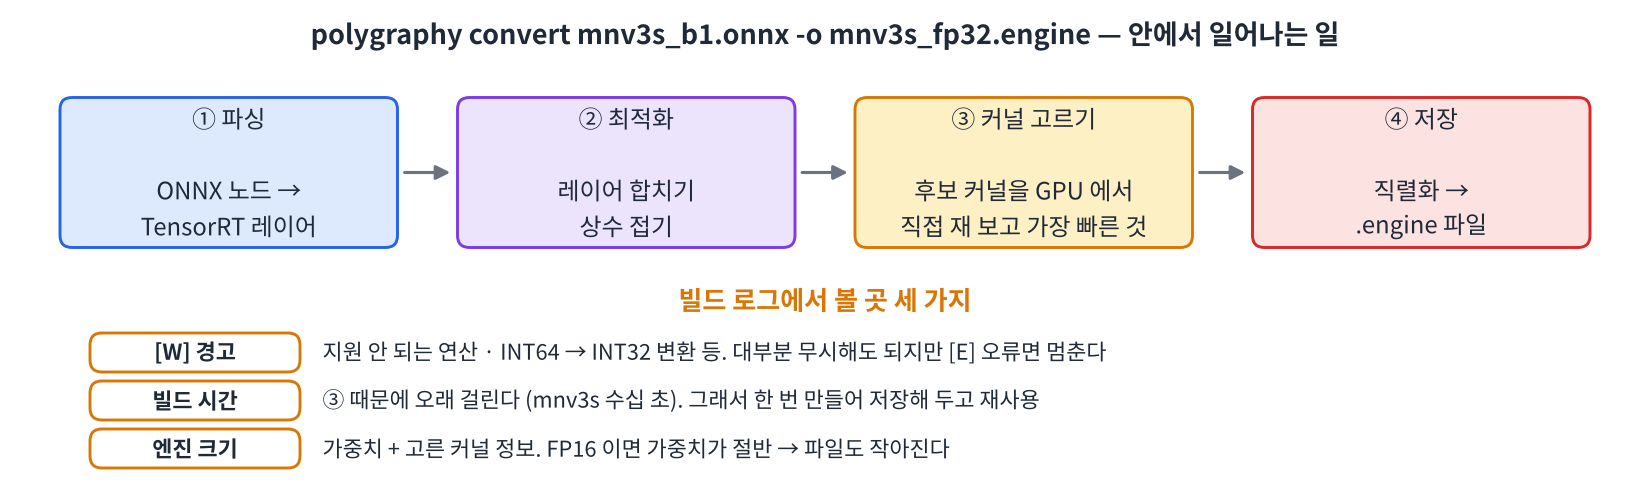

In [ ]:
#@title 🖼 그림 — polygraphy convert — 안에서 일어나는 일
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f2_convert.png", embed=True, width=880))

**문제 2-1** `mnv3s_b1.onnx` 를 FP32 엔진 `mnv3s_fp32_cli.engine` 으로 바꾸세요. 하위 명령은 `convert`, 출력 파일은 `-o`. **빌드에 수십 초 걸립니다 — 한 번만 누르고 기다리세요.**

In [ ]:
t0 = time.time()
rc = sh("polygraphy ____ mnv3s_b1.onnx -o mnv3s_fp32_cli.engine", log="build_fp32.log")
print(f"\n종료 코드 {rc} · 걸린 시간 {time.time() - t0:.0f} 초")

In [ ]:
assert rc == 0 and os.path.exists("mnv3s_fp32_cli.engine"); print("✅ 첫 엔진 완성 —", f"{os.path.getsize('mnv3s_fp32_cli.engine') / 1e6:.1f} MB")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACnQwID0gdGltZS50aW1lKCkKcmMgPSBzaCgicG9seWdyYXBoeSBjb252"
    "ZXJ0IG1udjNzX2IxLm9ubnggLW8gbW52M3NfZnAzMl9jbGkuZW5naW5lIiwgbG9nPSJidWlsZF9mcDMyLmxvZyIp"
    "CnByaW50KGYiXG7sooXro4wg7L2U65OcIHtyY30gwrcg6rG466awIOyLnOqwhCB7dGltZS50aW1lKCkgLSB0MDou"
    "MGZ9IOy0iCIpCgrwn5KhIO2VtOyEpArsooXro4wg7L2U65OcIDAgPSDshLHqs7UuIOyLnOqwhOydtCDsmKTrnpgg"
    "6rG466as64qUIOydtOycoOuKlCDqt7jrprzsnZgg4pGiIOKAlCDroIjsnbTslrTrp4jri6Qg7ZuE67O0IOy7pOuE"
    "kOydhCDsnbQgR1BVIOyXkOyEnCDsp4HsoJEg64+M66CkIOuztOqzoCDqsIDsnqUg67mg66W4IOqyg+ydhCDqs6Dr"
    "pbTquLAg65WM66y47J6F64uI64ukLg=="
).decode("utf-8"))

**문제 2-2** **로그에서 볼 곳 세 가지** — 전체 로그 `build_fp32.log` 에서 ① 경고 `[W]` 줄 수 ② `[E]` 오류 줄 수 ③ 빌드 시간 줄을 찾고, ONNX 와 엔진의 **파일 크기**를 비교하세요.

In [ ]:
log = open("build_fp32.log").read().splitlines()
warn = [l for l in log if l.startswith("[W]")]
err = [l for l in log if l.startswith("[____]")]
took = [l for l in log if "engine building" in l or "Finished" in l]
print("경고", len(warn), "줄 · 오류", len(err), "줄")
for l in warn[:3] + took[-1:]:
    print("  ", l[:130])
sizes = {f: os.path.getsize(f) / 1e6 for f in ["mnv3s_b1.onnx", "mnv3s_fp32_cli.engine"]}
print({k: f"{v:.1f} MB" for k, v in sizes.items()})

In [ ]:
assert len(err) == 0 and all(l.startswith("[E]") for l in err) and len(sizes) == 2
print("✅ 오류 0 — 경고는 읽어 보고 넘어간다")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmxvZyA9IG9wZW4oImJ1aWxkX2ZwMzIubG9nIikucmVhZCgpLnNwbGl0"
    "bGluZXMoKQp3YXJuID0gW2wgZm9yIGwgaW4gbG9nIGlmIGwuc3RhcnRzd2l0aCgiW1ddIildCmVyciA9IFtsIGZv"
    "ciBsIGluIGxvZyBpZiBsLnN0YXJ0c3dpdGgoIltFXSIpXQp0b29rID0gW2wgZm9yIGwgaW4gbG9nIGlmICJlbmdp"
    "bmUgYnVpbGRpbmciIGluIGwgb3IgIkZpbmlzaGVkIiBpbiBsXQpwcmludCgi6rK96rOgIiwgbGVuKHdhcm4pLCAi"
    "7KSEIMK3IOyYpOulmCIsIGxlbihlcnIpLCAi7KSEIikKZm9yIGwgaW4gd2Fybls6M10gKyB0b29rWy0xOl06CiAg"
    "ICBwcmludCgiICAiLCBsWzoxMzBdKQpzaXplcyA9IHtmOiBvcy5wYXRoLmdldHNpemUoZikgLyAxZTYgZm9yIGYg"
    "aW4gWyJtbnYzc19iMS5vbm54IiwgIm1udjNzX2ZwMzJfY2xpLmVuZ2luZSJdfQpwcmludCh7azogZiJ7djouMWZ9"
    "IE1CIiBmb3IgaywgdiBpbiBzaXplcy5pdGVtcygpfSkKCvCfkqEg7ZW07ISkCltXXSDripQg6rK96rOgICjqs4Ts"
    "ho0g7KeE7ZaJKSwgW0VdIOuKlCDsmKTrpZggKOu5jOuTnCDsi6TtjKgpLiDtnZTtlZwg6rK96rOgOiAnSU5UNjQg"
    "6rCA7KSR7LmY66W8IElOVDMyIOuhnCDrsJTqv6jri6QnIOKAlCDrrLTsi5ztlbTrj4Qg65Cp64uI64ukLgrsl5Ts"
    "p4Qg7YyM7J287JeQ64qUIOqwgOykkey5mCArIOqzoOuluCDsu6TrhJAg7KCV67O06rCAIOuTpOyWtCDsnojslrQg"
    "T05OWCDsmYAg7YGs6riw6rCAIOu5hOyKt+2VmOqxsOuCmCDsobDquIgg64uk66aF64uI64ukLiDroZzqt7gg66y4"
    "6rWs64qUIOuyhOyghOuniOuLpCDsobDquIjslKkg64uk66aF64uI64ukLg=="
).decode("utf-8"))

### 🔁 바꿔보기 — 옵션 하나: `--fp16`

같은 명령에 `--fp16` 만 붙여 FP16 엔진을 만들고 크기를 비교합니다 (6교시에서 자세히).

In [ ]:
sh("polygraphy convert mnv3s_b1.onnx --fp16 -o mnv3s_fp16_cli.engine", log="build_fp16.log", tail=3)
for f in ["mnv3s_fp32_cli.engine", "mnv3s_fp16_cli.engine"]:
    print(f, f"{os.path.getsize(f) / 1e6:.1f} MB")

#### ⚠️ 자주 하는 실수

- 빌드 셀을 여러 번 누름 → 빌드가 겹쳐 더 오래 걸리고 GPU 메모리가 모자랄 수 있습니다. 한 번 누르고 기다리기.
- `[W]` 경고를 오류로 착각 → 종료 코드 0 이면 성공. `[E]` 와 종료 코드를 보세요.
- 엔진 파일을 다른 컴퓨터 · 다른 Colab GPU (A100 등) 로 가져가 실행 → 버전 · GPU 가 다르면 읽지 못합니다. ONNX 를 가져가 다시 빌드.

#### 📌 2교시 정리

- `polygraphy convert 모델.onnx -o 엔진.engine` (+ `--fp16`).
- 빌드 = 파싱 → 최적화 → **커널 고르기 (오래 걸림)** → 저장. 로그는 `[E]` · `[W]` · 빌드 시간.

## 3교시 — 명령 한 줄로 비교하기: `polygraphy run --onnxrt --trt`

엔진이 빨라도 **답이 같아야** 씁니다 (Day 3 실험 원칙 3). `polygraphy run` 은 같은 무작위 입력을 ONNX Runtime 과 TensorRT 에 넣고 출력을 비교해 **PASSED / FAILED** 를 알려 줍니다.

> 🎬 **애니메이션** [D4-3 비교 · atol · rtol](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

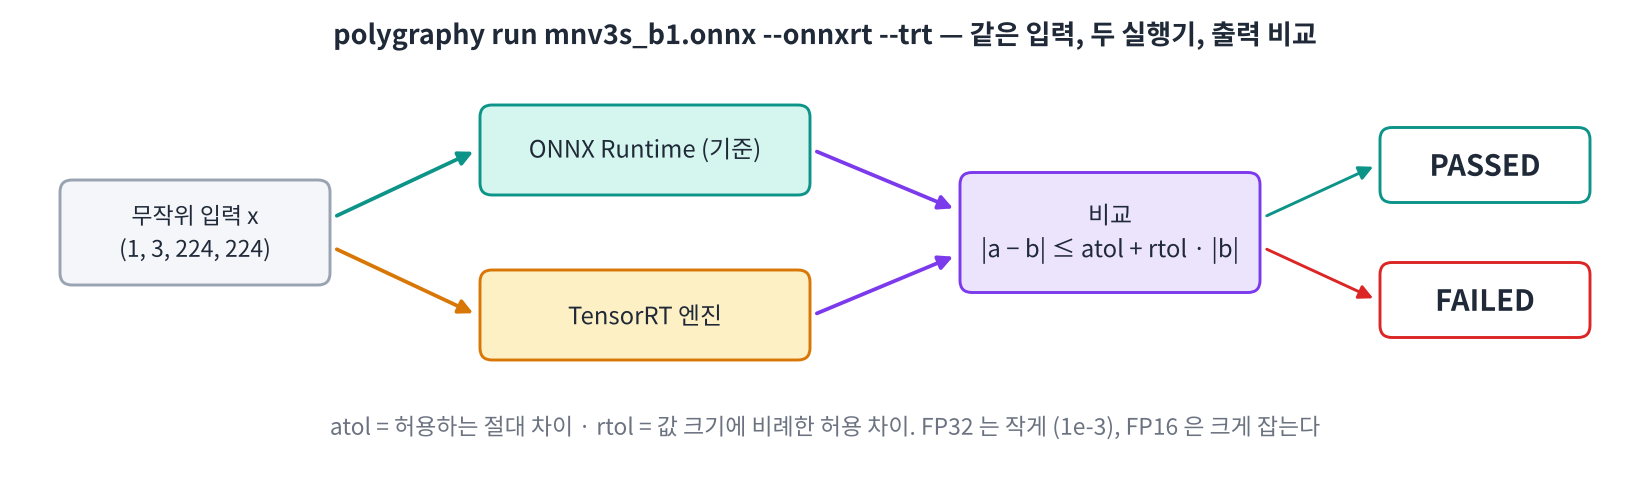

In [ ]:
#@title 🖼 그림 — polygraphy run — 같은 입력, 두 실행기
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f3_compare.png", embed=True, width=880))

**문제 3-1** FP32 엔진을 ONNX Runtime 과 비교하세요. 실행기 두 개는 `--onnxrt` 와 `--trt`, 허용 오차는 `--atol 1e-3 --rtol 1e-3`.

In [ ]:
rc32 = sh("polygraphy run mnv3s_b1.onnx --onnxrt ____ --atol 1e-3 --rtol 1e-3", log="cmp_fp32.log", tail=6)

In [ ]:
assert rc32 == 0 and "PASSED" in open("cmp_fp32.log").read(); print("✅ FP32 엔진 = ONNX Runtime (허용 오차 안)")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACnJjMzIgPSBzaCgicG9seWdyYXBoeSBydW4gbW52M3NfYjEub25ueCAt"
    "LW9ubnhydCAtLXRydCAtLWF0b2wgMWUtMyAtLXJ0b2wgMWUtMyIsIGxvZz0iY21wX2ZwMzIubG9nIiwgdGFpbD02"
    "KQoK8J+SoSDtlbTshKQKLS10cnQg66W8IOyjvOuptCBwb2x5Z3JhcGh5IOqwgCDslYjsl5DshJwg7JeU7KeE7J2E"
    "IOyDiOuhnCDruYzrk5ztlZwg65KkIOu5hOq1kO2VqeuLiOuLpCAo6re4656Y7IScIOuYkCDsiJjsi60g7LSIKS4K"
    "J0Fic29sdXRlIERpZmZlcmVuY2UgLi4uIG1heD0nIOqwgCDsi6TsoJwg7LWc64yAIOywqOydtCDigJQgMWUtMyDr"
    "s7Tri6Qg7Zuo7JSsIOyekeycvOuptCBGUDMyIOyXlOynhOydgCDsgqzsi6Tsg4Eg6rCZ7J2AIOuLteyeheuLiOuL"
    "pC4="
).decode("utf-8"))

**문제 3-2** **판정을 읽는 함수** — 로그 파일을 받아 마지막 판정 `"PASSED"` / `"FAILED"` 와 최대 절대 차이 (`max=` 뒤의 숫자, 없으면 `None`) 를 돌려주는 `verdict(log_path)` 를 완성하세요. 그다음 FP16 엔진을 **같은 엄격한 기준**과 **느슨한 기준**으로 비교해 봅니다.

In [ ]:
def verdict(log_path):
    text = open(log_path).read()
    result = "PASSED" if re.search(r"\bPASSED \| Runtime", text) else "____"
    m = re.findall(r"Absolute Difference.*?max=([0-9.eE+-]+)", text)
    return result, (float(m[-1]) if m else None)

sh("polygraphy run mnv3s_b1.onnx --onnxrt --trt --fp16 --atol 1e-3 --rtol 1e-3", log="cmp_fp16_strict.log", tail=3)
sh("polygraphy run mnv3s_b1.onnx --onnxrt --trt --fp16 --atol 5e-2 --rtol 5e-2", log="cmp_fp16_loose.log", tail=3)
for f in ["cmp_fp32.log", "cmp_fp16_strict.log", "cmp_fp16_loose.log"]:
    print(f.ljust(22), verdict(f))

In [ ]:
assert verdict("cmp_fp32.log")[0] == "PASSED" and all(verdict(f)[0] in ("PASSED", "FAILED") for f in ["cmp_fp16_strict.log", "cmp_fp16_loose.log"])
print("✅ FP16 엄격:", verdict("cmp_fp16_strict.log")[0], "· 느슨:", verdict("cmp_fp16_loose.log")[0])

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmRlZiB2ZXJkaWN0KGxvZ19wYXRoKToKICAgIHRleHQgPSBvcGVuKGxv"
    "Z19wYXRoKS5yZWFkKCkKICAgIHJlc3VsdCA9ICJQQVNTRUQiIGlmIHJlLnNlYXJjaChyIlxiUEFTU0VEIFx8IFJ1"
    "bnRpbWUiLCB0ZXh0KSBlbHNlICJGQUlMRUQiCiAgICBtID0gcmUuZmluZGFsbChyIkFic29sdXRlIERpZmZlcmVu"
    "Y2UuKj9tYXg9KFswLTkuZUUrLV0rKSIsIHRleHQpCiAgICByZXR1cm4gcmVzdWx0LCAoZmxvYXQobVstMV0pIGlm"
    "IG0gZWxzZSBOb25lKQoKc2goInBvbHlncmFwaHkgcnVuIG1udjNzX2IxLm9ubnggLS1vbm54cnQgLS10cnQgLS1m"
    "cDE2IC0tYXRvbCAxZS0zIC0tcnRvbCAxZS0zIiwgbG9nPSJjbXBfZnAxNl9zdHJpY3QubG9nIiwgdGFpbD0zKQpz"
    "aCgicG9seWdyYXBoeSBydW4gbW52M3NfYjEub25ueCAtLW9ubnhydCAtLXRydCAtLWZwMTYgLS1hdG9sIDVlLTIg"
    "LS1ydG9sIDVlLTIiLCBsb2c9ImNtcF9mcDE2X2xvb3NlLmxvZyIsIHRhaWw9MykKZm9yIGYgaW4gWyJjbXBfZnAz"
    "Mi5sb2ciLCAiY21wX2ZwMTZfc3RyaWN0LmxvZyIsICJjbXBfZnAxNl9sb29zZS5sb2ciXToKICAgIHByaW50KGYu"
    "bGp1c3QoMjIpLCB2ZXJkaWN0KGYpKQoK8J+SoSDtlbTshKQKRlAxNiDsnYAg7Jyg7Zqo7Iir7J6Q6rCAIOyVvSAz"
    "7J6Q66as6528IDFlLTMg6riw7KSA7Jy866Gc64qUIEZBSUxFRCDqsIAg64KY7Jik64qUIOydvOydtCDtnZTtlanr"
    "i4jri6QuIEZBSUxFRCA9ICfti4DroLjri6QnIOqwgCDslYTri4jrnbwgJ+ydtCDquLDspIDrs7Tri6Qg7LCo7J20"
    "6rCAIO2BrOuLpCcuCuq4sOykgOydhCDsoJXtlZjripQg6rKD7J2AIOyCrOuejCDigJQg6re4656Y7IScIDbqtZDs"
    "i5zsl5AgJ+u2hOulmCDqsrDqs7wgKOygle2ZleuPhCkg6rCAIOqwmeydgOqwgCcg66GcIOuLpOyLnCDtjJDri6jt"
    "lanri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- FP16 에 FP32 와 같은 atol 을 씀 → 거의 항상 FAILED. 정밀도에 맞는 기준 + 정확도로 판단.
- 무작위 입력 한 번 PASSED 로 '완벽하다' 고 결론 → 실제 데이터 (6교시 MNIST) 로도 확인.
- `--trt` 만 쓰고 `--onnxrt` 를 빠뜨림 → 비교 대상이 없어 실행만 합니다.

#### 📌 3교시 정리

- `polygraphy run 모델.onnx --onnxrt --trt [--fp16] --atol … --rtol …` → PASSED / FAILED.
- 판정 식: |a − b| ≤ atol + rtol · |b|. FP32 는 엄격하게, FP16 은 느슨하게 + 정확도로.

## 4교시 — Python 으로 엔진 빌드 → `build_engine()`

`polygraphy convert` 가 안에서 하던 일을 **코드 여섯 단계**로 다시 합니다. 셀 하나에 한 단계씩.

> 🎬 **애니메이션** [D4-4 빌드 여섯 단계](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

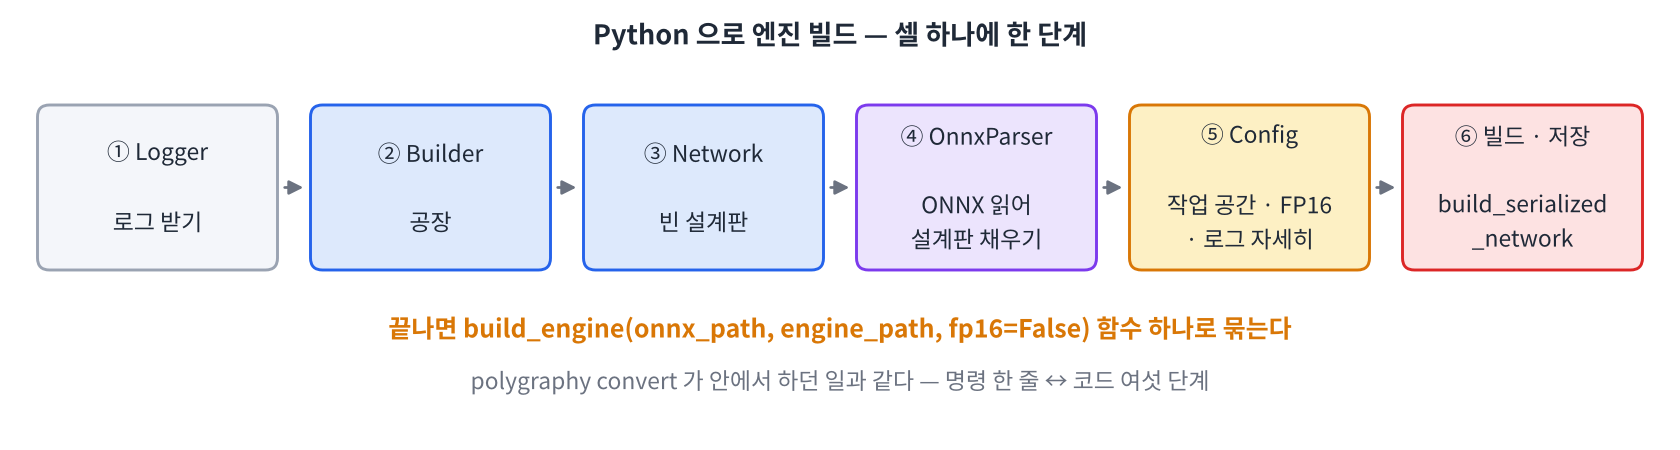

In [ ]:
#@title 🖼 그림 — Python 으로 엔진 빌드 — 여섯 단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f4_build.png", embed=True, width=900))

In [ ]:
# ① Logger — TensorRT 가 하는 말을 받는 곳. WARNING 이상만 보이게
LOGGER = trt.Logger(trt.Logger.WARNING)

# ② Builder — 엔진을 만드는 공장
builder = trt.Builder(LOGGER)

# ③ Network — 빈 설계판 (0 = 기본 설정: 배치를 shape 에 그대로 적는 explicit batch)
network = builder.create_network(0)
print("빈 설계판 레이어 수:", network.num_layers)

**문제 4-1** ④ **OnnxParser** 로 `mnv3s_b1.onnx` 를 읽어 설계판을 채우세요. 파일에서 바로 읽는 메서드는 `parse_from_file`. 실패하면 오류를 모두 출력합니다.

In [ ]:
parser = trt.OnnxParser(network, LOGGER)
ok = parser.____("mnv3s_b1.onnx")
if not ok:
    for i in range(parser.num_errors):
        print("파싱 오류:", parser.get_error(i))
inp = network.get_input(0)
print("파싱 성공:", ok, "| 레이어", network.num_layers, "| 입력", inp.name, tuple(inp.shape), "| 출력", network.get_output(0).name)

In [ ]:
assert ok and network.num_layers > 0 and tuple(network.get_input(0).shape) == (1, 3, 224, 224)
print("✅ ONNX 노드", len(onnx.load("mnv3s_b1.onnx").graph.node), "개 → TensorRT 레이어", network.num_layers, "개 (아직 합치기 전)")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACnBhcnNlciA9IHRydC5Pbm54UGFyc2VyKG5ldHdvcmssIExPR0dFUikK"
    "b2sgPSBwYXJzZXIucGFyc2VfZnJvbV9maWxlKCJtbnYzc19iMS5vbm54IikKaWYgbm90IG9rOgogICAgZm9yIGkg"
    "aW4gcmFuZ2UocGFyc2VyLm51bV9lcnJvcnMpOgogICAgICAgIHByaW50KCLtjIzsi7Eg7Jik66WYOiIsIHBhcnNl"
    "ci5nZXRfZXJyb3IoaSkpCmlucCA9IG5ldHdvcmsuZ2V0X2lucHV0KDApCnByaW50KCLtjIzsi7Eg7ISx6rO1OiIs"
    "IG9rLCAifCDroIjsnbTslrQiLCBuZXR3b3JrLm51bV9sYXllcnMsICJ8IOyeheugpSIsIGlucC5uYW1lLCB0dXBs"
    "ZShpbnAuc2hhcGUpLCAifCDstpzroKUiLCBuZXR3b3JrLmdldF9vdXRwdXQoMCkubmFtZSkKCvCfkqEg7ZW07ISk"
    "Cu2MjOyLsSDsp4Htm4TsnZgg66CI7J207Ja0IOyImOuKlCBPTk5YIOuFuOuTnCDsiJjsmYAg67mE7Iq37ZWp64uI"
    "64ukLiDtlansuZjquLAgKDfqtZDsi5wpIOuKlCDikaUg67mM65OcIOuVjCDsnbzslrTrgqnri4jri6QuCu2MjOyL"
    "sSDsmKTrpZjsnZgg64yA67aA67aE7J2AICdUZW5zb3JSVCDqsIAg66qo66W064qUIOyXsOyCsCcg4oCUIERheSAy"
    "IDfqtZDsi5zsspjrn7wg7KeA7JuQIOyXsOyCsCDsobDtlansnLzroZwg67CU6r+UIOuLpOyLnCBleHBvcnQg7ZWp"
    "64uI64ukLg=="
).decode("utf-8"))

**문제 4-2** ⑤ **Config** — 빌드 옵션입니다. 작업 공간 메모리 (`WORKSPACE`) 를 1 GB 로 정하고, 7교시에 레이어를 자세히 보려고 `profiling_verbosity` 를 `DETAILED` 로. ⑥ **빌드 · 저장** — `build_serialized_network` 의 결과를 파일로 씁니다.

In [ ]:
config = builder.create_builder_config()
config.set_memory_pool_limit(trt.MemoryPoolType.____, 1 << 30)       # 1 GB
config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED

t0 = time.time()
blob = builder.build_serialized_network(network, config)              # ⑥ — 수십 초
with open("mnv3s_fp32.engine", "wb") as f:
    f.write(blob)
print(f"빌드 {time.time() - t0:.0f} 초 → mnv3s_fp32.engine {os.path.getsize('mnv3s_fp32.engine') / 1e6:.1f} MB")

In [ ]:
assert blob is not None and os.path.getsize("mnv3s_fp32.engine") > 1e6; print("✅ 코드로 만든 첫 엔진")

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmNvbmZpZyA9IGJ1aWxkZXIuY3JlYXRlX2J1aWxkZXJfY29uZmlnKCkK"
    "Y29uZmlnLnNldF9tZW1vcnlfcG9vbF9saW1pdCh0cnQuTWVtb3J5UG9vbFR5cGUuV09SS1NQQUNFLCAxIDw8IDMw"
    "KSAgICAgICAjIDEgR0IKY29uZmlnLnByb2ZpbGluZ192ZXJib3NpdHkgPSB0cnQuUHJvZmlsaW5nVmVyYm9zaXR5"
    "LkRFVEFJTEVECgp0MCA9IHRpbWUudGltZSgpCmJsb2IgPSBidWlsZGVyLmJ1aWxkX3NlcmlhbGl6ZWRfbmV0d29y"
    "ayhuZXR3b3JrLCBjb25maWcpICAgICAgICAgICAgICAjIOKRpSDigJQg7IiY7IutIOy0iAp3aXRoIG9wZW4oIm1u"
    "djNzX2ZwMzIuZW5naW5lIiwgIndiIikgYXMgZjoKICAgIGYud3JpdGUoYmxvYikKcHJpbnQoZiLruYzrk5wge3Rp"
    "bWUudGltZSgpIC0gdDA6LjBmfSDstIgg4oaSIG1udjNzX2ZwMzIuZW5naW5lIHtvcy5wYXRoLmdldHNpemUoJ21u"
    "djNzX2ZwMzIuZW5naW5lJykgLyAxZTY6LjFmfSBNQiIpCgrwn5KhIO2VtOyEpApXT1JLU1BBQ0UgPSDsu6TrhJDs"
    "nbQg6rOE7IKwIOykkeyXkCDsnqDquZAg7JOw64qUIEdQVSDrqZTrqqjrpqwg7IOB7ZWcLiDrhIjrrLQg7J6R7Jy8"
    "66m0IOu5oOuluCDsu6TrhJDsnYQg66q7IOqzoOumheuLiOuLpC4K67mM65Oc6rCAIOyLpO2MqO2VmOuptCBibG9i"
    "IOydtCBOb25lIOKAlCDqt7jrlYzripQg7JyE7Kq9IOuhnOq3uCAoW0VdKSDrpbwg67SF64uI64ukLg=="
).decode("utf-8"))

**문제 4-3** 여섯 단계를 함수 `build_engine(onnx_path, engine_path, fp16=False)` 로 묶으세요. `fp16=True` 면 Config 에 **FP16 플래그 한 줄**을 더합니다 (`config.set_flag(trt.BuilderFlag.FP16)`). SimpleConvNet 으로 확인합니다.

In [ ]:
def build_engine(onnx_path, engine_path, fp16=False):
    builder = trt.Builder(LOGGER)
    network = builder.create_network(0)
    parser = trt.OnnxParser(network, LOGGER)
    if not parser.parse_from_file(onnx_path):
        raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
    config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED
    if fp16:
        config.set_flag(trt.BuilderFlag.____)
    blob = builder.build_serialized_network(network, config)
    if blob is None:
        raise RuntimeError("빌드 실패 — 위 로그를 확인하세요")
    with open(engine_path, "wb") as f:
        f.write(blob)
    return engine_path

t0 = time.time()
build_engine("mnist_cnn_b1.onnx", "cnn_fp32.engine")
print(f"cnn_fp32.engine {os.path.getsize('cnn_fp32.engine') / 1e6:.2f} MB · {time.time() - t0:.0f} 초")

In [ ]:
assert "fp16" in inspect.signature(build_engine).parameters and os.path.exists("cnn_fp32.engine")
print("✅ build_engine 완성 — 6교시 · 8교시에서 그대로 씁니다")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACmRlZiBidWlsZF9lbmdpbmUob25ueF9wYXRoLCBlbmdpbmVfcGF0aCwg"
    "ZnAxNj1GYWxzZSk6CiAgICBidWlsZGVyID0gdHJ0LkJ1aWxkZXIoTE9HR0VSKQogICAgbmV0d29yayA9IGJ1aWxk"
    "ZXIuY3JlYXRlX25ldHdvcmsoMCkKICAgIHBhcnNlciA9IHRydC5Pbm54UGFyc2VyKG5ldHdvcmssIExPR0dFUikK"
    "ICAgIGlmIG5vdCBwYXJzZXIucGFyc2VfZnJvbV9maWxlKG9ubnhfcGF0aCk6CiAgICAgICAgcmFpc2UgUnVudGlt"
    "ZUVycm9yKCJcbiIuam9pbihzdHIocGFyc2VyLmdldF9lcnJvcihpKSkgZm9yIGkgaW4gcmFuZ2UocGFyc2VyLm51"
    "bV9lcnJvcnMpKSkKICAgIGNvbmZpZyA9IGJ1aWxkZXIuY3JlYXRlX2J1aWxkZXJfY29uZmlnKCkKICAgIGNvbmZp"
    "Zy5zZXRfbWVtb3J5X3Bvb2xfbGltaXQodHJ0Lk1lbW9yeVBvb2xUeXBlLldPUktTUEFDRSwgMSA8PCAzMCkKICAg"
    "IGNvbmZpZy5wcm9maWxpbmdfdmVyYm9zaXR5ID0gdHJ0LlByb2ZpbGluZ1ZlcmJvc2l0eS5ERVRBSUxFRAogICAg"
    "aWYgZnAxNjoKICAgICAgICBjb25maWcuc2V0X2ZsYWcodHJ0LkJ1aWxkZXJGbGFnLkZQMTYpCiAgICBibG9iID0g"
    "YnVpbGRlci5idWlsZF9zZXJpYWxpemVkX25ldHdvcmsobmV0d29yaywgY29uZmlnKQogICAgaWYgYmxvYiBpcyBO"
    "b25lOgogICAgICAgIHJhaXNlIFJ1bnRpbWVFcnJvcigi67mM65OcIOyLpO2MqCDigJQg7JyEIOuhnOq3uOulvCDt"
    "mZXsnbjtlZjshLjsmpQiKQogICAgd2l0aCBvcGVuKGVuZ2luZV9wYXRoLCAid2IiKSBhcyBmOgogICAgICAgIGYu"
    "d3JpdGUoYmxvYikKICAgIHJldHVybiBlbmdpbmVfcGF0aAoKdDAgPSB0aW1lLnRpbWUoKQpidWlsZF9lbmdpbmUo"
    "Im1uaXN0X2Nubl9iMS5vbm54IiwgImNubl9mcDMyLmVuZ2luZSIpCnByaW50KGYiY25uX2ZwMzIuZW5naW5lIHtv"
    "cy5wYXRoLmdldHNpemUoJ2Nubl9mcDMyLmVuZ2luZScpIC8gMWU2Oi4yZn0gTUIgwrcge3RpbWUudGltZSgpIC0g"
    "dDA6LjBmfSDstIgiKQoK8J+SoSDtlbTshKQKRlAxNiDsnYAgJ+2XiOudvScg7J6F64uI64ukIOKAlCAnRlAxNiDs"
    "nbQg642UIOu5oOuluCDroIjsnbTslrTripQgRlAxNiDsnLzroZwg7ZW064+EIOuQnOuLpCcuIFRlbnNvclJUIOqw"
    "gCDroIjsnbTslrTrp4jri6Qg7J6sIOuztOqzoCBGUDMyIOuhnCDrgqjquLDquLDrj4Qg7ZWp64uI64ukLgpUZW5z"
    "b3JSVCAxMC4xMiDsnbTtm4Qg7J20IO2UjOuemOq3uOuKlCAn7Jik656Y65CcIOuwqeyLnSAod2VhayB0eXBpbmcp"
    "JyDsnLzroZwg7ZGc7Iuc65CY6rOgLCAxMS54IOyXkOyEnOuKlCDsl4bslrTsoYzsirXri4jri6Qg4oCUIOq3uOue"
    "mOyEnCDsmKTripggMTAueCDroZwg6rOg7KCV7ZaI7Iq164uI64ukLg=="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `parse_from_file` 결과를 확인하지 않고 빌드 → 빈 설계판으로 빌드해 `None` 이 나옵니다. 파싱 → 확인 → 빌드.
- Builder · Network · Config 를 함수 밖 전역 변수로 재사용 → 두 번째 빌드에 이전 설계가 섞입니다. 빌드마다 새로.
- 배치가 자유로운 ONNX (`["batch", ...]`) 를 그대로 빌드 → optimization profile 이 없다는 오류. 오늘은 `_b1.onnx`.

#### 📌 4교시 정리

- ① Logger ② Builder ③ Network ④ OnnxParser ⑤ Config (WORKSPACE · DETAILED · FP16) ⑥ build_serialized_network → 파일.
- `build_engine(onnx, engine, fp16=False)` — polygraphy convert 와 같은 일.

## 5교시 — Python 으로 엔진 실행 → `trt_runner()`

엔진 파일을 읽어 실행합니다. ONNX Runtime 은 NumPy 를 그대로 받았지만, TensorRT 는 **GPU 메모리 주소**만 받습니다. GPU 메모리는 **PyTorch CUDA 텐서**로 준비합니다.

> 🎬 **애니메이션** [D4-5 엔진 실행 — 주소 알려 주기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

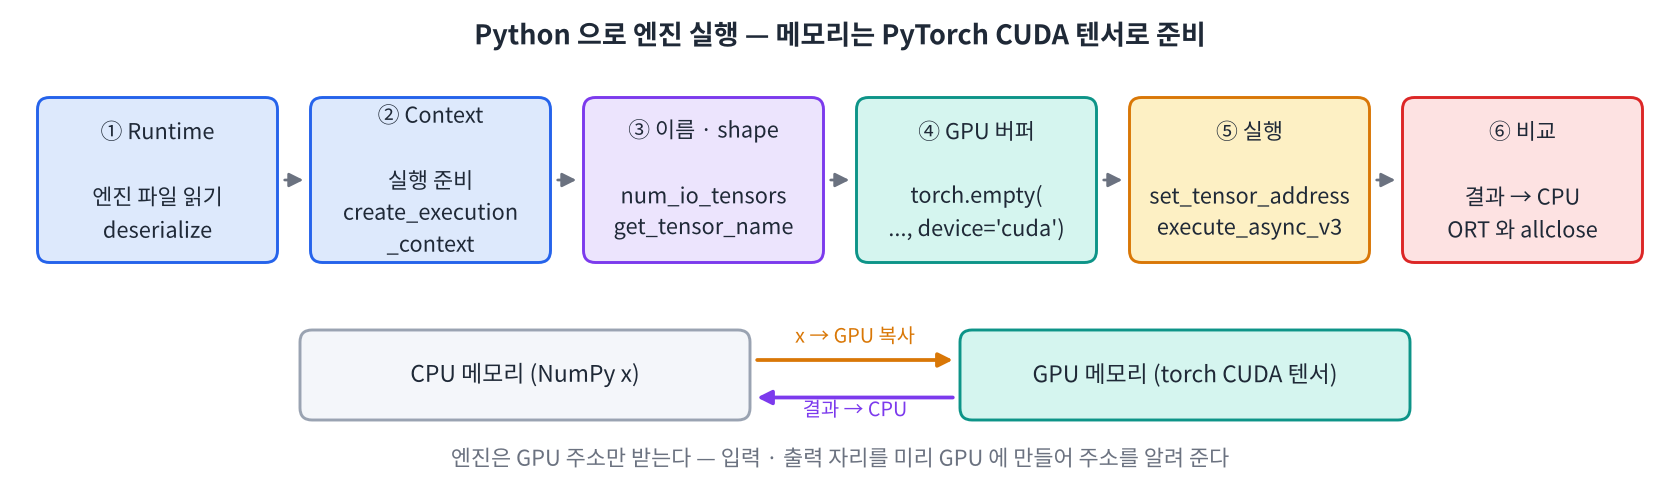

In [ ]:
#@title 🖼 그림 — 엔진 실행 — 여섯 단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f5_run.png", embed=True, width=900))

In [ ]:
# ① Runtime — 엔진 파일을 읽는 도구 (빌드할 때의 Builder 에 해당)
RUNTIME = trt.Runtime(LOGGER)
engine = RUNTIME.deserialize_cuda_engine(open("mnv3s_fp32.engine", "rb").read())

# ② Context — 실행 한 번에 필요한 상태 (입출력 주소 등). 엔진 하나로 여러 개 만들 수 있다
context = engine.create_execution_context()
print("엔진:", engine is not None, "| 입출력 텐서 수:", engine.num_io_tensors)

**문제 5-1** ③ **이름 · shape 확인** — 엔진의 입출력 텐서를 하나씩 꺼내 이름 · 입력/출력 · shape · 자료형을 표로 만드세요. 이름은 `get_tensor_name(i)`.

In [ ]:
io = []
for i in range(engine.num_io_tensors):
    name = engine.____(i)
    io.append({"name": name, "mode": str(engine.get_tensor_mode(name)).split(".")[-1],
               "shape": tuple(engine.get_tensor_shape(name)), "dtype": str(engine.get_tensor_dtype(name)).split(".")[-1]})
display(pd.DataFrame(io))
in_name = [d["name"] for d in io if d["mode"] == "INPUT"][0]
out_name = [d["name"] for d in io if d["mode"] == "OUTPUT"][0]

In [ ]:
assert in_name == "input" and out_name == "logits" and io[0]["shape"] == (1, 3, 224, 224)
print("✅ 이름은 export 때 붙인 그대로 — Day 1 5교시의 input_names · output_names")

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACmlvID0gW10KZm9yIGkgaW4gcmFuZ2UoZW5naW5lLm51bV9pb190ZW5z"
    "b3JzKToKICAgIG5hbWUgPSBlbmdpbmUuZ2V0X3RlbnNvcl9uYW1lKGkpCiAgICBpby5hcHBlbmQoeyJuYW1lIjog"
    "bmFtZSwgIm1vZGUiOiBzdHIoZW5naW5lLmdldF90ZW5zb3JfbW9kZShuYW1lKSkuc3BsaXQoIi4iKVstMV0sCiAg"
    "ICAgICAgICAgICAgICJzaGFwZSI6IHR1cGxlKGVuZ2luZS5nZXRfdGVuc29yX3NoYXBlKG5hbWUpKSwgImR0eXBl"
    "Ijogc3RyKGVuZ2luZS5nZXRfdGVuc29yX2R0eXBlKG5hbWUpKS5zcGxpdCgiLiIpWy0xXX0pCmRpc3BsYXkocGQu"
    "RGF0YUZyYW1lKGlvKSkKaW5fbmFtZSA9IFtkWyJuYW1lIl0gZm9yIGQgaW4gaW8gaWYgZFsibW9kZSJdID09ICJJ"
    "TlBVVCJdWzBdCm91dF9uYW1lID0gW2RbIm5hbWUiXSBmb3IgZCBpbiBpbyBpZiBkWyJtb2RlIl0gPT0gIk9VVFBV"
    "VCJdWzBdCgrwn5KhIO2VtOyEpApEYXkgMSDsl5DshJwgJ+ydtOumhOydhCDrtpnsl6zslbwg64uk66W4IO2UhOuh"
    "nOq3uOueqOydtCDssL7snYQg7IiYIOyeiOuLpCcg6rOgIO2VnCDsnbTsnKDqsIAg7Jes6riwIOKAlCBUZW5zb3JS"
    "VCDrj4Qg7J2066aE7Jy866GcIOyehey2nOugpeydhCDssL7sirXri4jri6Qu"
).decode("utf-8"))

**문제 5-2** ④ **GPU 버퍼** → ⑤ **실행** → ⑥ **비교**. 입력 · 출력 자리를 GPU 에 만들고 (`device="cuda"`), 그 주소 (`data_ptr()`) 를 Context 에 알려 준 뒤 실행합니다. 결과를 CPU 로 가져와 ORT CPU 출력 `ref` 와 비교하세요.

In [ ]:
d_in = torch.from_numpy(x1).to("____")                                       # ④ CPU → GPU 복사
d_out = torch.empty(tuple(engine.get_tensor_shape(out_name)), dtype=torch.float32, device="cuda")
context.set_tensor_address(in_name, d_in.data_ptr())                         # ⑤ 주소 알려 주기
context.set_tensor_address(out_name, d_out.data_ptr())
context.execute_async_v3(torch.cuda.current_stream().cuda_stream)            # ⑤ 실행 (비동기)
torch.cuda.synchronize()                                                     #    끝날 때까지 기다리기
y_trt = d_out.cpu().numpy()                                                  # ⑥ GPU → CPU
diff32 = float(np.abs(y_trt - ref).max())
print(f"TensorRT FP32 vs ORT CPU 최대 차이 {diff32:.1e} | allclose(1e-3): {np.allclose(y_trt, ref, atol=1e-3)} | top-1 같음: {y_trt.argmax() == ref.argmax()}")

In [ ]:
assert y_trt.shape == ref.shape and diff32 < 1e-3; print("✅ 3교시 polygraphy 의 PASSED 를 코드로 직접 확인")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmRfaW4gPSB0b3JjaC5mcm9tX251bXB5KHgxKS50bygiY3VkYSIpICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIyDikaMgQ1BVIOKGkiBHUFUg67O17IKsCmRfb3V0"
    "ID0gdG9yY2guZW1wdHkodHVwbGUoZW5naW5lLmdldF90ZW5zb3Jfc2hhcGUob3V0X25hbWUpKSwgZHR5cGU9dG9y"
    "Y2guZmxvYXQzMiwgZGV2aWNlPSJjdWRhIikKY29udGV4dC5zZXRfdGVuc29yX2FkZHJlc3MoaW5fbmFtZSwgZF9p"
    "bi5kYXRhX3B0cigpKSAgICAgICAgICAgICAgICAgICAgICAgICAjIOKRpCDso7zshowg7JWM66CkIOyjvOq4sApj"
    "b250ZXh0LnNldF90ZW5zb3JfYWRkcmVzcyhvdXRfbmFtZSwgZF9vdXQuZGF0YV9wdHIoKSkKY29udGV4dC5leGVj"
    "dXRlX2FzeW5jX3YzKHRvcmNoLmN1ZGEuY3VycmVudF9zdHJlYW0oKS5jdWRhX3N0cmVhbSkgICAgICAgICAgICAj"
    "IOKRpCDsi6TtlokgKOu5hOuPmeq4sCkKdG9yY2guY3VkYS5zeW5jaHJvbml6ZSgpICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAjICAgIOuBneuCoCDrlYzquYzsp4Ag6riw64uk66as"
    "6riwCnlfdHJ0ID0gZF9vdXQuY3B1KCkubnVtcHkoKSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAgIyDikaUgR1BVIOKGkiBDUFUKZGlmZjMyID0gZmxvYXQobnAuYWJzKHlfdHJ0IC0gcmVm"
    "KS5tYXgoKSkKcHJpbnQoZiJUZW5zb3JSVCBGUDMyIHZzIE9SVCBDUFUg7LWc64yAIOywqOydtCB7ZGlmZjMyOi4x"
    "ZX0gfCBhbGxjbG9zZSgxZS0zKToge25wLmFsbGNsb3NlKHlfdHJ0LCByZWYsIGF0b2w9MWUtMyl9IHwgdG9wLTEg"
    "6rCZ7J2MOiB7eV90cnQuYXJnbWF4KCkgPT0gcmVmLmFyZ21heCgpfSIpCgrwn5KhIO2VtOyEpApleGVjdXRlX2Fz"
    "eW5jX3YzIOuKlCAn7Iuc7J6R7ZW0IOuRrCcg66eMIO2VmOqzoCDrsJTroZwg64+M7JWE7Ji164uI64ukICjruYTr"
    "j5nquLApLiBzeW5jaHJvbml6ZSDsl4bsnbQg6rKw6rO866W8IOydveycvOuptCDslYTsp4Eg67mE7Ja0IOyeiOyd"
    "hCDsiJgg7J6I7Iq164uI64ukLgooLmNwdSgpIOuPhCDquLDri6TroKQg7KO87KeA66eMLCDsi5zqsITsnYQg7J60"
    "IOuVjOuKlCBzeW5jaHJvbml6ZSDrpbwg66qF7Iuc7ZWY64qUIOyKteq0gOydhCDrk6TsnbTshLjsmpQuKQ=="
).decode("utf-8"))

**문제 5-3** ④~⑥ 을 함수로 묶습니다. `trt_runner(engine_path)` 는 엔진을 읽고 버퍼를 **한 번만** 준비한 뒤, NumPy 입력을 받아 NumPy 출력을 돌려주는 함수 `run(x)` 를 돌려줍니다. 매번 버퍼를 새로 만들지 않는 것이 빠른 비결입니다.

In [ ]:
def trt_runner(engine_path):
    eng = RUNTIME.deserialize_cuda_engine(open(engine_path, "rb").read())
    ctx = eng.create_execution_context()
    names = [eng.get_tensor_name(i) for i in range(eng.num_io_tensors)]
    i_name = [n for n in names if eng.get_tensor_mode(n) == trt.TensorIOMode.INPUT][0]
    o_name = [n for n in names if eng.get_tensor_mode(n) == trt.TensorIOMode.____][0]
    d_i = torch.empty(tuple(eng.get_tensor_shape(i_name)), dtype=torch.float32, device="cuda")
    d_o = torch.empty(tuple(eng.get_tensor_shape(o_name)), dtype=torch.float32, device="cuda")
    ctx.set_tensor_address(i_name, d_i.data_ptr())
    ctx.set_tensor_address(o_name, d_o.data_ptr())

    def run(x):
        d_i.copy_(torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)))   # CPU → GPU (같은 자리에 덮어쓰기)
        ctx.execute_async_v3(torch.cuda.current_stream().cuda_stream)
        torch.cuda.synchronize()
        return d_o.cpu().numpy()

    run.engine, run.context = eng, ctx          # 엔진이 사라지지 않게 붙잡아 두기
    return run

run32 = trt_runner("mnv3s_fp32.engine")
print("최대 차이:", f"{np.abs(run32(x1) - ref).max():.1e}")

In [ ]:
x2 = np.random.rand(1, 3, 224, 224).astype(np.float32)
assert np.allclose(run32(x2), cpu_sess.run(None, {"input": x2})[0], atol=1e-3) and np.allclose(run32(x1), ref, atol=1e-3)
print("✅ trt_runner 완성 — 입력이 바뀌어도 맞는 답 (Day 5 에서 TRTInfer 클래스로 발전)")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACmRlZiB0cnRfcnVubmVyKGVuZ2luZV9wYXRoKToKICAgIGVuZyA9IFJV"
    "TlRJTUUuZGVzZXJpYWxpemVfY3VkYV9lbmdpbmUob3BlbihlbmdpbmVfcGF0aCwgInJiIikucmVhZCgpKQogICAg"
    "Y3R4ID0gZW5nLmNyZWF0ZV9leGVjdXRpb25fY29udGV4dCgpCiAgICBuYW1lcyA9IFtlbmcuZ2V0X3RlbnNvcl9u"
    "YW1lKGkpIGZvciBpIGluIHJhbmdlKGVuZy5udW1faW9fdGVuc29ycyldCiAgICBpX25hbWUgPSBbbiBmb3IgbiBp"
    "biBuYW1lcyBpZiBlbmcuZ2V0X3RlbnNvcl9tb2RlKG4pID09IHRydC5UZW5zb3JJT01vZGUuSU5QVVRdWzBdCiAg"
    "ICBvX25hbWUgPSBbbiBmb3IgbiBpbiBuYW1lcyBpZiBlbmcuZ2V0X3RlbnNvcl9tb2RlKG4pID09IHRydC5UZW5z"
    "b3JJT01vZGUuT1VUUFVUXVswXQogICAgZF9pID0gdG9yY2guZW1wdHkodHVwbGUoZW5nLmdldF90ZW5zb3Jfc2hh"
    "cGUoaV9uYW1lKSksIGR0eXBlPXRvcmNoLmZsb2F0MzIsIGRldmljZT0iY3VkYSIpCiAgICBkX28gPSB0b3JjaC5l"
    "bXB0eSh0dXBsZShlbmcuZ2V0X3RlbnNvcl9zaGFwZShvX25hbWUpKSwgZHR5cGU9dG9yY2guZmxvYXQzMiwgZGV2"
    "aWNlPSJjdWRhIikKICAgIGN0eC5zZXRfdGVuc29yX2FkZHJlc3MoaV9uYW1lLCBkX2kuZGF0YV9wdHIoKSkKICAg"
    "IGN0eC5zZXRfdGVuc29yX2FkZHJlc3Mob19uYW1lLCBkX28uZGF0YV9wdHIoKSkKCiAgICBkZWYgcnVuKHgpOgog"
    "ICAgICAgIGRfaS5jb3B5Xyh0b3JjaC5mcm9tX251bXB5KG5wLmFzY29udGlndW91c2FycmF5KHgsIGR0eXBlPW5w"
    "LmZsb2F0MzIpKSkgICAjIENQVSDihpIgR1BVICjqsJnsnYAg7J6Q66as7JeQIOuNruyWtOyTsOq4sCkKICAgICAg"
    "ICBjdHguZXhlY3V0ZV9hc3luY192Myh0b3JjaC5jdWRhLmN1cnJlbnRfc3RyZWFtKCkuY3VkYV9zdHJlYW0pCiAg"
    "ICAgICAgdG9yY2guY3VkYS5zeW5jaHJvbml6ZSgpCiAgICAgICAgcmV0dXJuIGRfby5jcHUoKS5udW1weSgpCgog"
    "ICAgcnVuLmVuZ2luZSwgcnVuLmNvbnRleHQgPSBlbmcsIGN0eCAgICAgICAgICAjIOyXlOynhOydtCDsgqzrnbzs"
    "p4Dsp4Ag7JWK6rKMIOu2meyeoeyVhCDrkZDquLAKICAgIHJldHVybiBydW4KCnJ1bjMyID0gdHJ0X3J1bm5lcigi"
    "bW52M3NfZnAzMi5lbmdpbmUiKQpwcmludCgi7LWc64yAIOywqOydtDoiLCBmIntucC5hYnMocnVuMzIoeDEpIC0g"
    "cmVmKS5tYXgoKTouMWV9IikKCvCfkqEg7ZW07ISkCuuyhO2NvOuKlCDtlZwg67KIIOunjOuTpOqzoCDso7zshozr"
    "j4Qg7ZWcIOuyiCDslYzroKQg7KSN64uI64ukLiBydW4g7J2AICfrs7Xsgqwg4oaSIOyLpO2WiSDihpIg6riw64uk"
    "66as6riwIOKGkiDqsIDsoLjsmKTquLAnIOunjCDigJQg6re4656Y7IScIOu5oOumheuLiOuLpC4KeCDqsIAg64uk"
    "66W4IO2BrOq4sOuptCBjb3B5XyDsl5DshJwg7Jik66WY6rCAIOuCqeuLiOuLpCAo67Cw7LmYIDEg6rOg7KCVIOyX"
    "lOynhCku"
).decode("utf-8"))

**문제 5-4** **얼마나 빨라졌나** — `bench_fn` 으로 ORT CPU · ORT CUDA EP · TensorRT FP32 를 같은 입력 `x1` 로 재서 표로 만드세요. 세 줄 모두 'CPU 의 NumPy 입력 → CPU 의 NumPy 출력' 을 재므로 공평합니다.

In [ ]:
cuda_sess = ort.InferenceSession("mnv3s_b1.onnx", providers=CUDA)
rows = [{"runtime": "ORT CPU", **bench(cpu_sess, x1)},
        {"runtime": "ORT CUDA", **bench(cuda_sess, x1)},
        {"runtime": "TRT FP32", **bench_fn(lambda: ____(x1))}]
df5 = pd.DataFrame(rows)
df5["speedup"] = df5["mean"].iloc[0] / df5["mean"]
display(df5)
print("ORT CUDA 세션 실제 실행기:", cuda_sess.get_providers()[0])

In [ ]:
assert df5.runtime.tolist() == ["ORT CPU", "ORT CUDA", "TRT FP32"] and abs(df5.speedup.iloc[0] - 1) < 1e-9
print(f"✅ TensorRT FP32 는 ORT CPU 의 {df5.speedup.iloc[2]:.1f}배")

In [ ]:
#@title 🔒 정답 보기 5-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTQg4pSA4pSACmN1ZGFfc2VzcyA9IG9ydC5JbmZlcmVuY2VTZXNzaW9uKCJtbnYzc19i"
    "MS5vbm54IiwgcHJvdmlkZXJzPUNVREEpCnJvd3MgPSBbeyJydW50aW1lIjogIk9SVCBDUFUiLCAqKmJlbmNoKGNw"
    "dV9zZXNzLCB4MSl9LAogICAgICAgIHsicnVudGltZSI6ICJPUlQgQ1VEQSIsICoqYmVuY2goY3VkYV9zZXNzLCB4"
    "MSl9LAogICAgICAgIHsicnVudGltZSI6ICJUUlQgRlAzMiIsICoqYmVuY2hfZm4obGFtYmRhOiBydW4zMih4MSkp"
    "fV0KZGY1ID0gcGQuRGF0YUZyYW1lKHJvd3MpCmRmNVsic3BlZWR1cCJdID0gZGY1WyJtZWFuIl0uaWxvY1swXSAv"
    "IGRmNVsibWVhbiJdCmRpc3BsYXkoZGY1KQpwcmludCgiT1JUIENVREEg7IS47IWYIOyLpOygnCDsi6TtlonquLA6"
    "IiwgY3VkYV9zZXNzLmdldF9wcm92aWRlcnMoKVswXSkKCvCfkqEg7ZW07ISkCmJlbmNoX2ZuIOydgCAn7ZWcIOuy"
    "iCDsi6TtlontlZjripQg7ZWo7IiYJyDrpbwg67Cb7Iq164uI64ukIOKAlCBsYW1iZGE6IHJ1bjMyKHgxKS4g67Cw"
    "7LmYIDEgwrcg7J6R7J2AIOuqqOuNuOydtOudvCDrs7Xsgqwg7Iuc6rCE7J20IO2BsCDrqqvsnYQg7LCo7KeA7ZW0"
    "LApUZW5zb3JSVCDsnZgg7J2065Od7J20IOuqqOuNuCDqs4TsgrAg7Iuc6rCE67O064ukIOyekeqyjCDrs7Tsnbwg"
    "7IiYIOyeiOyKteuLiOuLpCAoRGF5IDMgNeq1kOyLnOyZgCDqsJnsnYAg7J207JygKS4="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- NumPy 배열을 그대로 `set_tensor_address` 에 넣음 → TensorRT 는 **GPU 주소**만 받습니다. CUDA 텐서의 `data_ptr()`.
- `execute_async_v3` 뒤에 기다리지 않고 시간을 잼 → 실행이 끝나기 전 시간이라 엄청 빠르게 보입니다.
- 실행할 때마다 `torch.empty(..., device="cuda")` 를 새로 만들고 주소를 다시 알려 줌 → 느립니다. 버퍼는 한 번.
- 입력을 `float64` 로 넣음 → `np.random.rand` 의 기본은 float64. `.astype(np.float32)`.

#### 📌 5교시 정리

- ① Runtime → 엔진 ② Context ③ `get_tensor_name` · shape ④ CUDA 텐서 버퍼 ⑤ `set_tensor_address` · `execute_async_v3` · 기다리기 ⑥ CPU 로 · 비교.
- `trt_runner(engine)` → `run(x)` — 버퍼는 한 번만 준비.

## 6교시 — FP16 으로 더 빠르게: 속도 · 정확도

FP16 은 숫자 하나를 16비트 (2바이트) 로 저장합니다. 메모리가 절반이고, T4 의 **Tensor Core** 가 FP16 을 훨씬 빨리 계산합니다. 대신 표현 범위와 정밀도가 줄어듭니다.

> 🎬 **애니메이션** [D4-6 FP32 vs FP16](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

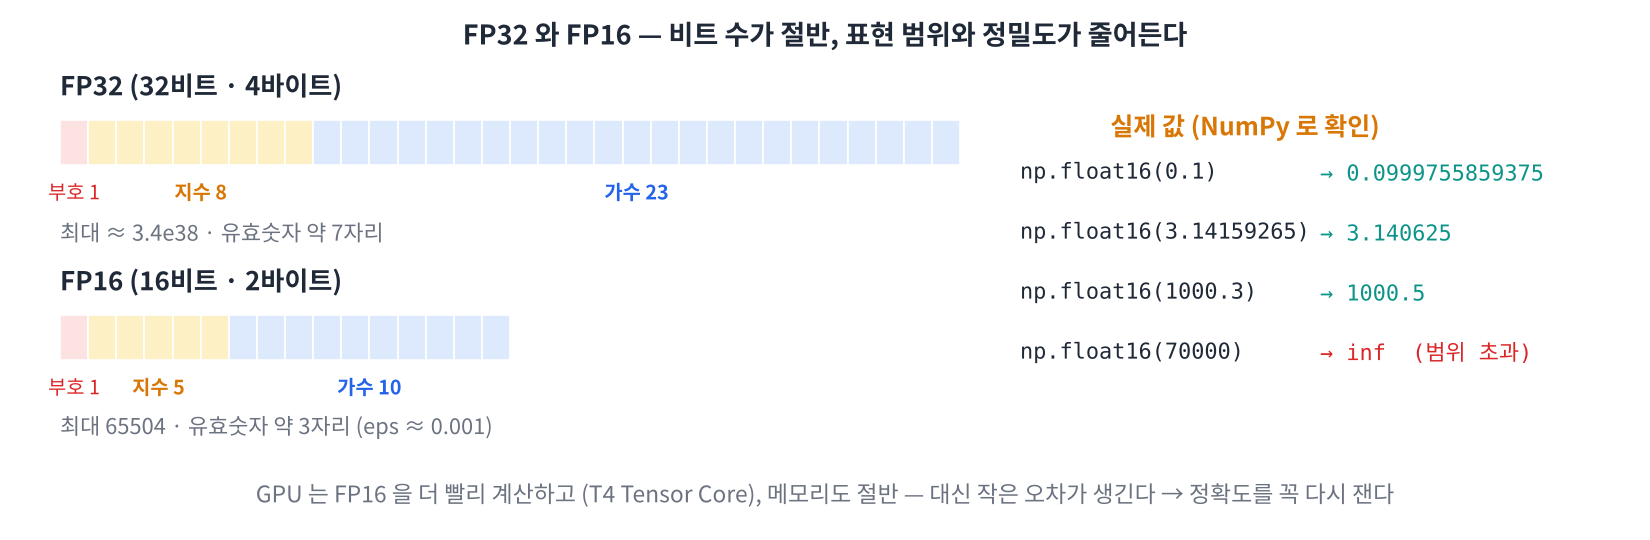

In [ ]:
#@title 🖼 그림 — FP32 와 FP16
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f6_fp16.png", embed=True, width=880))

**문제 6-1** **FP16 손으로 만져 보기** — NumPy 의 `np.float16` 으로 몇 개의 숫자를 FP16 으로 바꿔 보고, 표현할 수 있는 가장 큰 수와 '1 다음 수' 까지의 간격 (`eps`) 을 확인하세요.

In [ ]:
for v in [0.1, 3.14159265, 1000.3, 70000.0]:
    print(f"{v:>12} → FP16 {float(np.____(v))!r}")
fi = np.finfo(np.float16)
print("FP16 최대:", fi.max, "| eps:", fi.eps, "| FP32 eps:", np.finfo(np.float32).eps)

In [ ]:
assert float(np.float16(0.1)) == 0.0999755859375 and np.isinf(np.float16(70000.0)) and fi.max == 65504
print("✅ 0.1 도 정확히 저장되지 않고, 65504 를 넘으면 inf")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmZvciB2IGluIFswLjEsIDMuMTQxNTkyNjUsIDEwMDAuMywgNzAwMDAu"
    "MF06CiAgICBwcmludChmInt2Oj4xMn0g4oaSIEZQMTYge2Zsb2F0KG5wLmZsb2F0MTYodikpIXJ9IikKZmkgPSBu"
    "cC5maW5mbyhucC5mbG9hdDE2KQpwcmludCgiRlAxNiDstZzrjIA6IiwgZmkubWF4LCAifCBlcHM6IiwgZmkuZXBz"
    "LCAifCBGUDMyIGVwczoiLCBucC5maW5mbyhucC5mbG9hdDMyKS5lcHMpCgrwn5KhIO2VtOyEpAplcHMg4omIIDAu"
    "MDAxIOKGkiBGUDE2IOydgCDsnKDtmqjsiKvsnpAg7JW9IDPsnpDrpqwuIDEwMDAg6re87LKY7JeQ7ISc64qUIOqw"
    "hOqyqeydtCAwLjUgKDEwMDAuMyDihpIgMTAwMC41KS4K7Iug6rK966ed7J2YIO2ZnOyEseqwkiDCtyDqsIDspJHs"
    "uZjripQg64yA67aA67aEIOydtCDrspTsnIQg7JWI7J206528IEZQMTYg7Jy866Gc64+EIOqysOqzvOqwgCDqsbDs"
    "nZgg6rCZ7Iq164uI64ukIOKAlCDtlZjsp4Drp4wgJ+qxsOydmCcg66W8IOq8rSDsnqwg67SQ7JW8IO2VqeuLiOuL"
    "pC4="
).decode("utf-8"))

**문제 6-2** `build_engine(..., fp16=True)` 로 `mnv3s_fp16.engine` 을 만들고, FP32 엔진과 **파일 크기 · 출력 차이 · 속도**를 비교하세요.

In [ ]:
t0 = time.time()
build_engine("mnv3s_b1.onnx", "mnv3s_fp16.engine", fp16=____)
print(f"FP16 빌드 {time.time() - t0:.0f} 초")
run16 = trt_runner("mnv3s_fp16.engine")
y16 = run16(x1)
diff16 = float(np.abs(y16 - ref).max())
r32, r16 = bench_fn(lambda: run32(x1)), bench_fn(lambda: run16(x1))
for name, r, f in [("FP32", r32, "mnv3s_fp32.engine"), ("FP16", r16, "mnv3s_fp16.engine")]:
    print(f"{name}: {os.path.getsize(f) / 1e6:.1f} MB · 평균 {r['mean']:.3f} ms · p95 {r['p95']:.3f} · {r['fps']:.0f} FPS")
print(f"FP16 vs ORT CPU 최대 차이 {diff16:.1e} (FP32 는 {diff32:.1e}) · top-1 같음: {y16.argmax() == ref.argmax()}")

In [ ]:
assert os.path.getsize("mnv3s_fp16.engine") < os.path.getsize("mnv3s_fp32.engine") and diff16 >= 0
print(f"✅ FP16: 파일 {os.path.getsize('mnv3s_fp16.engine') / os.path.getsize('mnv3s_fp32.engine'):.2f}배 · 속도 {r32['mean'] / r16['mean']:.1f}배")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACnQwID0gdGltZS50aW1lKCkKYnVpbGRfZW5naW5lKCJtbnYzc19iMS5v"
    "bm54IiwgIm1udjNzX2ZwMTYuZW5naW5lIiwgZnAxNj1UcnVlKQpwcmludChmIkZQMTYg67mM65OcIHt0aW1lLnRp"
    "bWUoKSAtIHQwOi4wZn0g7LSIIikKcnVuMTYgPSB0cnRfcnVubmVyKCJtbnYzc19mcDE2LmVuZ2luZSIpCnkxNiA9"
    "IHJ1bjE2KHgxKQpkaWZmMTYgPSBmbG9hdChucC5hYnMoeTE2IC0gcmVmKS5tYXgoKSkKcjMyLCByMTYgPSBiZW5j"
    "aF9mbihsYW1iZGE6IHJ1bjMyKHgxKSksIGJlbmNoX2ZuKGxhbWJkYTogcnVuMTYoeDEpKQpmb3IgbmFtZSwgciwg"
    "ZiBpbiBbKCJGUDMyIiwgcjMyLCAibW52M3NfZnAzMi5lbmdpbmUiKSwgKCJGUDE2IiwgcjE2LCAibW52M3NfZnAx"
    "Ni5lbmdpbmUiKV06CiAgICBwcmludChmIntuYW1lfToge29zLnBhdGguZ2V0c2l6ZShmKSAvIDFlNjouMWZ9IE1C"
    "IMK3IO2Pieq3oCB7clsnbWVhbiddOi4zZn0gbXMgwrcgcDk1IHtyWydwOTUnXTouM2Z9IMK3IHtyWydmcHMnXTou"
    "MGZ9IEZQUyIpCnByaW50KGYiRlAxNiB2cyBPUlQgQ1BVIOy1nOuMgCDssKjsnbQge2RpZmYxNjouMWV9IChGUDMy"
    "IOuKlCB7ZGlmZjMyOi4xZX0pIMK3IHRvcC0xIOqwmeydjDoge3kxNi5hcmdtYXgoKSA9PSByZWYuYXJnbWF4KCl9"
    "IikKCvCfkqEg7ZW07ISkCu2MjOydvOydgCDqsIDspJHsuZjqsIAg7KCI67CY7J20IOuQmOyWtCDsnpHslYTsp4Dq"
    "s6AsIOywqOydtOuKlCBGUDMyIOuztOuLpCDsiJjrsLF+7IiY7LKcIOuwsCDsu6Tsp5Hri4jri6QuCuyYpOuKmCBt"
    "bnYzcyDripQg6rCA7KSR7LmY6rCAIOustOyekeychOudvCAxMDAw6rCcIOygkOyImOqwgCDshJzroZwg67mE7Iq3"
    "7ZW0IHRvcC0xIOydtCDrsJTrgJQg7IiY64+EIOyeiOyKteuLiOuLpCDigJQg6re4656Y7IScICfsoJXtmZXrj4Qn"
    "IOuKlCDtlZnsirXrkJwg66qo642466GcIOuUsOuhnCDsnr3ri4jri6QgKDYtMyku"
).decode("utf-8"))

**문제 6-3** **정확도로 판단하기** — 학습된 SimpleConvNet 으로 MNIST 100장의 정확도를 ORT CPU · TRT FP32 · TRT FP16 으로 각각 구하세요. 입력은 Day 1 과 같이 `/ 255`, 한 장씩 (배치 1 엔진).

In [ ]:
d = np.load(fetch("mnist_sample.npz"))
X = (d["images"].astype(np.float32) / 255)[:, None]             # (100, 1, 28, 28)
Y = d["labels"]
build_engine("mnist_cnn_b1.onnx", "cnn_fp16.engine", fp16=True)
cnn_cpu = ort.InferenceSession("mnist_cnn_b1.onnx", providers=CPU)
runners = {"ORT CPU": lambda x: cnn_cpu.run(None, {"input": x})[0],
           "TRT FP32": trt_runner("cnn_fp32.engine"),
           "TRT FP16": trt_runner("cnn_fp16.engine")}
acc = {}
for name, f in runners.items():
    pred = np.array([f(X[i:i + 1]).argmax() for i in range(len(X))])
    acc[name] = float((pred == ____).mean())
print(acc)

In [ ]:
assert set(acc) == {"ORT CPU", "TRT FP32", "TRT FP16"} and all(0 <= v <= 1 for v in acc.values()) and acc["ORT CPU"] >= 0.95
print(f"✅ FP16 정확도 변화: {acc['TRT FP16'] - acc['ORT CPU']:+.2f} — 숫자 차이는 있어도 분류 결과는 거의 그대로")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACmQgPSBucC5sb2FkKGZldGNoKCJtbmlzdF9zYW1wbGUubnB6IikpClgg"
    "PSAoZFsiaW1hZ2VzIl0uYXN0eXBlKG5wLmZsb2F0MzIpIC8gMjU1KVs6LCBOb25lXSAgICAgICAgICAgICAjICgx"
    "MDAsIDEsIDI4LCAyOCkKWSA9IGRbImxhYmVscyJdCmJ1aWxkX2VuZ2luZSgibW5pc3RfY25uX2IxLm9ubngiLCAi"
    "Y25uX2ZwMTYuZW5naW5lIiwgZnAxNj1UcnVlKQpjbm5fY3B1ID0gb3J0LkluZmVyZW5jZVNlc3Npb24oIm1uaXN0"
    "X2Nubl9iMS5vbm54IiwgcHJvdmlkZXJzPUNQVSkKcnVubmVycyA9IHsiT1JUIENQVSI6IGxhbWJkYSB4OiBjbm5f"
    "Y3B1LnJ1bihOb25lLCB7ImlucHV0IjogeH0pWzBdLAogICAgICAgICAgICJUUlQgRlAzMiI6IHRydF9ydW5uZXIo"
    "ImNubl9mcDMyLmVuZ2luZSIpLAogICAgICAgICAgICJUUlQgRlAxNiI6IHRydF9ydW5uZXIoImNubl9mcDE2LmVu"
    "Z2luZSIpfQphY2MgPSB7fQpmb3IgbmFtZSwgZiBpbiBydW5uZXJzLml0ZW1zKCk6CiAgICBwcmVkID0gbnAuYXJy"
    "YXkoW2YoWFtpOmkgKyAxXSkuYXJnbWF4KCkgZm9yIGkgaW4gcmFuZ2UobGVuKFgpKV0pCiAgICBhY2NbbmFtZV0g"
    "PSBmbG9hdCgocHJlZCA9PSBZKS5tZWFuKCkpCnByaW50KGFjYykKCvCfkqEg7ZW07ISkCuyEuCDqsIDsp4Ag7Iuk"
    "7ZaJ6riw66W8IOqwmeydgCDrqqjslpHsnZgg7ZWo7IiYICh4IOKGkiDsoJDsiJgpIOuhnCDrp57strAg65GQ66m0"
    "IO2VnCDspIQg67CY67O166y47Jy866GcIOu5hOq1kO2VoCDsiJgg7J6I7Iq164uI64ukLgon7LWc64yAIOywqOyd"
    "tCcg64qUIEZQMTYg7JeQ7IScIOy7pOyguOuPhCwg67aE66WY7LKY65+8ICfqsIDsnqUg7YGwIOygkOyImCcg66eM"
    "IOuztOuKlCDsnbzsl5DshJzripQg6rKw6rO86rCAIOqxsOydmCDrsJTrgIzsp4Ag7JWK7Iq164uI64ukLiBEYXkg"
    "NSBZT0xPIOyXkOyEnOuKlCBtQVAg66GcIOqwmeydgCDtmZXsnbjsnYQg7ZWp64uI64ukLg=="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- FP16 엔진인데 입력을 `float16` 으로 바꿔 넣음 → 오늘 엔진의 입출력은 FP32 그대로입니다 (5-1 표의 dtype). 안쪽 계산만 FP16.
- 'FP16 은 무조건 2배 빠르다' → 복사 · 작은 레이어 · FP32 로 남은 레이어 때문에 모델마다 다릅니다. 재 보고 말하기.
- 정확도는 안 보고 속도만 기록 → 빨라도 틀리면 못 씁니다. 성능표에 정확도 열을 함께.

#### 📌 6교시 정리

- FP16 = 2바이트 · 최대 65504 · 유효숫자 약 3자리. T4 Tensor Core 로 빠름.
- `build_engine(..., fp16=True)` — Config 한 줄. 파일 ↓ · 속도 ↑ · 차이 ↑ → **정확도로 판단**.

## 7교시 — 왜 빨라졌나: 엔진 레이어 들여다보기

빌드할 때 `profiling_verbosity = DETAILED` 로 해 두었기 때문에, 엔진 안의 레이어 목록을 꺼내 볼 수 있습니다. **ONNX 노드 수 vs 엔진 레이어 수**를 비교하면 무엇이 합쳐졌는지 보입니다.

> 🎬 **애니메이션** [D4-7 레이어 합치기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

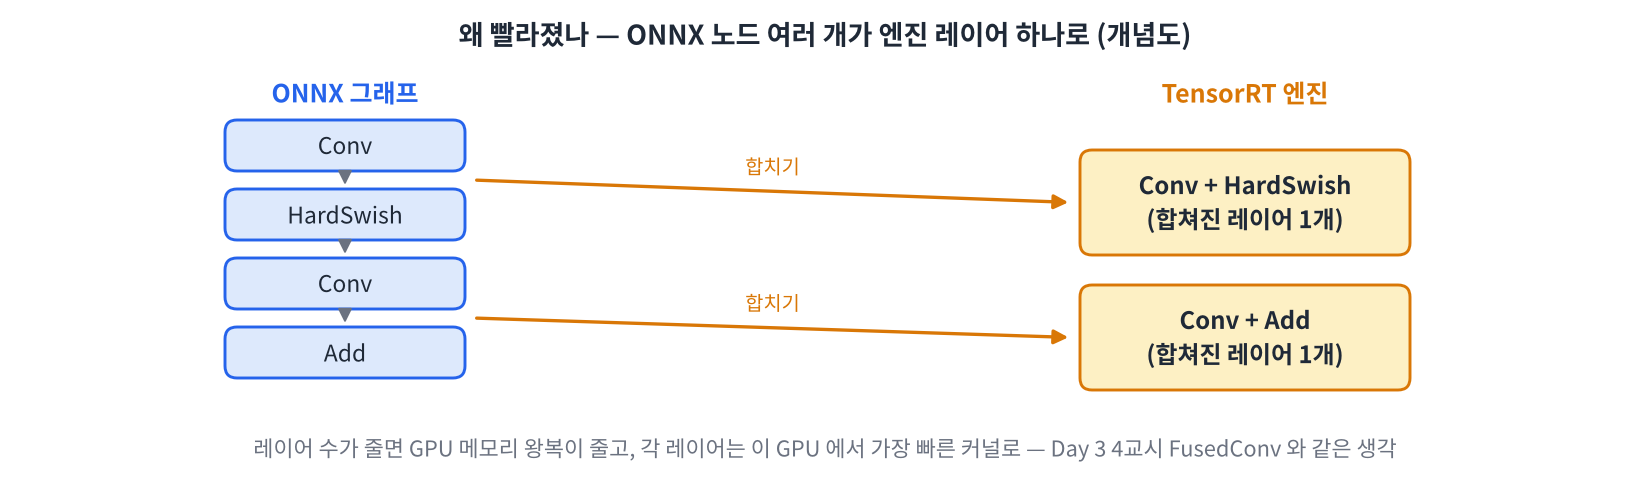

In [ ]:
#@title 🖼 그림 — ONNX 노드 → 엔진 레이어 (개념도)
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f7_fusion.png", embed=True, width=880))

**문제 7-1** **엔진 인스펙터** — `create_engine_inspector()` 로 FP32 엔진의 레이어 정보를 JSON 으로 꺼내, 레이어 이름 목록 `names` 를 만드세요. JSON 형식은 `trt.LayerInformationFormat.JSON`.

In [ ]:
insp = run32.engine.create_engine_inspector()
info = json.loads(insp.get_engine_information(trt.LayerInformationFormat.____))
layers = info["Layers"]
names = [l["Name"] if isinstance(l, dict) else l for l in layers]
n_onnx = len(onnx.load("mnv3s_b1.onnx").graph.node)
print(f"ONNX 노드 {n_onnx}개 → 엔진 레이어 {len(names)}개")
for n in names[:6]:
    print("  ", n[:110])

In [ ]:
assert len(names) > 0 and all(isinstance(n, str) for n in names); print("✅ 레이어", len(names), "개 — 이름에 ' + ' 가 있으면 합쳐진 레이어")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmluc3AgPSBydW4zMi5lbmdpbmUuY3JlYXRlX2VuZ2luZV9pbnNwZWN0"
    "b3IoKQppbmZvID0ganNvbi5sb2FkcyhpbnNwLmdldF9lbmdpbmVfaW5mb3JtYXRpb24odHJ0LkxheWVySW5mb3Jt"
    "YXRpb25Gb3JtYXQuSlNPTikpCmxheWVycyA9IGluZm9bIkxheWVycyJdCm5hbWVzID0gW2xbIk5hbWUiXSBpZiBp"
    "c2luc3RhbmNlKGwsIGRpY3QpIGVsc2UgbCBmb3IgbCBpbiBsYXllcnNdCm5fb25ueCA9IGxlbihvbm54LmxvYWQo"
    "Im1udjNzX2IxLm9ubngiKS5ncmFwaC5ub2RlKQpwcmludChmIk9OTlgg64W465OcIHtuX29ubnh96rCcIOKGkiDs"
    "l5Tsp4Qg66CI7J207Ja0IHtsZW4obmFtZXMpfeqwnCIpCmZvciBuIGluIG5hbWVzWzo2XToKICAgIHByaW50KCIg"
    "ICIsIG5bOjExMF0pCgrwn5KhIO2VtOyEpArtlanss5Dsp4Qg66CI7J207Ja064qUIOydtOumhOydtCAnQSArIEIn"
    "IOyymOufvCDsm5DrnpggT05OWCDrhbjrk5wg7J2066aE7J2EIOydtOyWtCDrtpnsnbgg66qo7JaR7J6F64uI64uk"
    "LiAnUmVmb3JtYXR0aW5nIENvcHlOb2RlJyDripQg642w7J207YSwIOuwsOy5mOulvCDrsJTqvrjripQg66CI7J20"
    "7Ja0IOKAlCBEYXkgMyA06rWQ7IucIEFMTCDroIjrsqjsnZggUmVvcmRlciDsmYAg6rCZ7J2AIOyXre2VoC4="
).decode("utf-8"))

**문제 7-2** **합쳐진 레이어 세기** — 이름에 `" + "` 가 들어 있는 레이어를 `fused` 로 모으고, 각 레이어가 ONNX 노드 몇 개를 품었는지 (`" + "` 로 나눈 조각 수) 세어 가장 많이 합친 레이어를 찾으세요. 데이터 배치 변환 레이어 (`Reformat` 이 이름에 있는) 도 세어 봅니다.

In [ ]:
fused = [n for n in names if " + " in n]
parts = [len(n.split(" + ")) for n in fused]
reformat = [n for n in names if "Reformat" in n]
print("합쳐진 레이어", len(fused), "개 · 여기에 들어간 ONNX 노드", sum(parts), "개 · 데이터 배치 변환", len(reformat), "개")
if fused:
    i = int(np.____(parts))
    print("가장 많이 합친 레이어 (", parts[i], "개):")
    for p in fused[i].split(" + "):
        print("   ", p[:100])

In [ ]:
assert len(fused) == len(parts) and all(p >= 2 for p in parts) and (not fused or parts[i] == max(parts))
print("✅ 합쳐진 레이어", len(fused), "개 — 메모리 왕복이 그만큼 줄었다")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmZ1c2VkID0gW24gZm9yIG4gaW4gbmFtZXMgaWYgIiArICIgaW4gbl0K"
    "cGFydHMgPSBbbGVuKG4uc3BsaXQoIiArICIpKSBmb3IgbiBpbiBmdXNlZF0KcmVmb3JtYXQgPSBbbiBmb3IgbiBp"
    "biBuYW1lcyBpZiAiUmVmb3JtYXQiIGluIG5dCnByaW50KCLtlanss5Dsp4Qg66CI7J207Ja0IiwgbGVuKGZ1c2Vk"
    "KSwgIuqwnCDCtyDsl6zquLDsl5Ag65Ok7Ja06rCEIE9OTlgg64W465OcIiwgc3VtKHBhcnRzKSwgIuqwnCDCtyDr"
    "jbDsnbTthLAg67Cw7LmYIOuzgO2ZmCIsIGxlbihyZWZvcm1hdCksICLqsJwiKQppZiBmdXNlZDoKICAgIGkgPSBp"
    "bnQobnAuYXJnbWF4KHBhcnRzKSkKICAgIHByaW50KCLqsIDsnqUg66eO7J20IO2Vqey5nCDroIjsnbTslrQgKCIs"
    "IHBhcnRzW2ldLCAi6rCcKToiKQogICAgZm9yIHAgaW4gZnVzZWRbaV0uc3BsaXQoIiArICIpOgogICAgICAgIHBy"
    "aW50KCIgICAiLCBwWzoxMDBdKQoK8J+SoSDtlbTshKQK67O07Ya1IENvbnYgKyDtmZzshLEg7ZWo7IiYIChIYXJk"
    "U3dpc2ggwrcgUmVsdSkg64KYIENvbnYgKyBBZGQg6rCAIO2VmOuCmOuhnCDtlanss5Dsp5Hri4jri6QuICdQV04o"
    "Li4uKScg7LKY65+8IOq0hO2YuOuhnCDrrLbsnbgg7J2066aE7J2AIOygkOuzhCAocG9pbnR3aXNlKSDsl7DsgrAg"
    "7Jes65+sIOqwnOulvCDtlansuZwg6rKDLgrrsoTsoITrp4jri6Qg7J2066aEIOuqqOyWkeydtCDsobDquIgg64uk"
    "66W066+A66GcICcgKyAnIOuhnCDshLwg7Iir7J6Q64qUICfrjIDrnrUnIOycvOuhnCDrtIXri4jri6Qu"
).decode("utf-8"))

**문제 7-3** **레이어 종류** — DETAILED 정보에는 레이어마다 `LayerType` 이 있습니다. 종류별 개수를 세어 상위 6개를 보고, Day 3 7교시 profiling (Conv 가 절반 이상) 과 연결해 보세요. CLI 로도 같은 목록을 볼 수 있습니다.

In [ ]:
types = collections.Counter(l.get("____", "?") if isinstance(l, dict) else "?" for l in layers)
print(types.most_common(6))
sh("polygraphy inspect model mnv3s_fp32.engine --show layers", log="inspect_fp32.log", tail=8)

In [ ]:
assert sum(types.values()) == len(layers); print("✅ 엔진 레이어 종류", len(types), "가지")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACnR5cGVzID0gY29sbGVjdGlvbnMuQ291bnRlcihsLmdldCgiTGF5ZXJU"
    "eXBlIiwgIj8iKSBpZiBpc2luc3RhbmNlKGwsIGRpY3QpIGVsc2UgIj8iIGZvciBsIGluIGxheWVycykKcHJpbnQo"
    "dHlwZXMubW9zdF9jb21tb24oNikpCnNoKCJwb2x5Z3JhcGh5IGluc3BlY3QgbW9kZWwgbW52M3NfZnAzMi5lbmdp"
    "bmUgLS1zaG93IGxheWVycyIsIGxvZz0iaW5zcGVjdF9mcDMyLmxvZyIsIHRhaWw9OCkKCvCfkqEg7ZW07ISkCkNv"
    "bnYg6rOE7Je0IOugiOydtOyWtCAo7J2066aE7JeQIENvbnZvbHV0aW9uIMK3IENhc2sg65OxKSDqsIAg6rCA7J6l"
    "IOunjuyKteuLiOuLpC4g6rCBIOugiOydtOyWtOyXkCDrjIDtlbQgVGVuc29yUlQg64qUIOydtCBHUFUg7JeQ7ISc"
    "IOqwgOyepSDruaDrpbgg7Luk64SQICh0YWN0aWMpIOydhCDqs6jrnbwg65GQ7JeI6rOgLArqt7jqsoPsnbQgJ+u5"
    "jOuTnOyXkCDsmKTrnpgg6rG466as7KeA66eMIOyLpO2WieydgCDruaDrpbgnIOydtOycoOyeheuLiOuLpC4gRGF5"
    "IDMgT1JUIOuKlCDsoJXtlbTsp4Qg6rec7LmZLCBUZW5zb3JSVCDripQgJ+yngeygkSDsnqwg67O06rOgJyDqs6Dr"
    "poXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `profiling_verbosity = DETAILED` 없이 빌드한 엔진을 인스펙트 → 이름만 나오고 `LayerType` 이 없습니다 (그래서 build_engine 에 넣어 둠).
- 레이어 수가 적을수록 무조건 빠르다고 단정 → 합치기 + 커널 선택 + FP16 이 함께 작용합니다. 결국 bench 로 확인.

#### 📌 7교시 정리

- 엔진 인스펙터 → JSON → 레이어 이름 · 종류. 이름의 ' + ' = 합쳐진 레이어.
- 빨라진 이유: ① 레이어 합치기 (메모리 왕복 ↓) ② 이 GPU 에서 재 보고 고른 커널 ③ FP16 (Tensor Core).

## 8교시 — 미니 프로젝트: 실행기 4가지 성능표

같은 `mnv3s_b1.onnx` 를 **ORT CPU · ORT CUDA · TensorRT FP32 · TensorRT FP16** 네 가지로 돌려 **속도 + 정확도**를 한 표로 만들고, Day 3 의 `ot_baseline.csv` 에 이어 붙입니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 4행 측정표 `cmp` — 같은 입력 · 같은 bench | 20 |
| 2 | 정확도 열 — ORT CPU 와의 최대 차이 · top-1 일치 | 20 |
| 3 | MNIST 정확도 표 — 같은 4가지 실행기로 SimpleConvNet | 20 |
| 4 | 속도 비교 — `speedup` 열 · 가장 빠른 실행기 | 20 |
| 5 | `ot_baseline.csv` 이어 붙이기 · 그래프 | 10 |
| 6 | 정리 · 추천 (마크다운 답변) | 10 |

엔진은 4~6교시에 만든 것을 그대로 씁니다 (`mnv3s_fp32.engine` · `mnv3s_fp16.engine` · `cnn_fp32.engine` · `cnn_fp16.engine`). 런타임이 끊겼다면 아래 '엔진 확인' 셀이 없는 엔진을 다시 빌드합니다.

> 🎬 **애니메이션** [D4-8 실행기 4가지 성능표](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/animation.html#d4-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day4/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

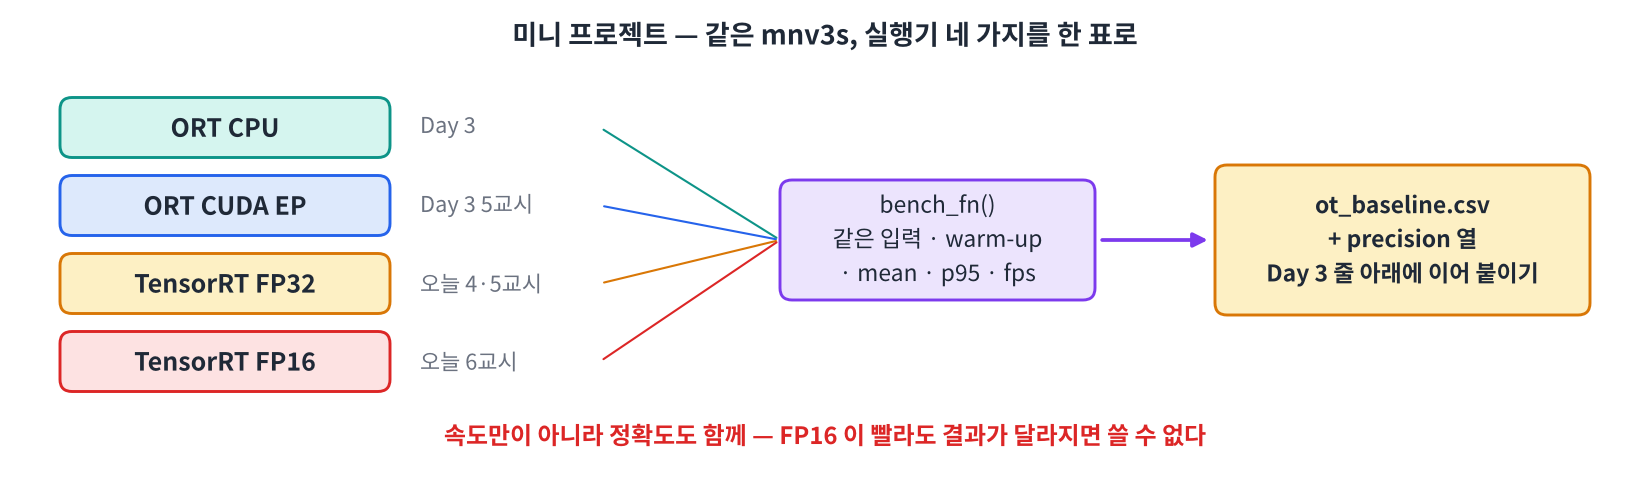

In [ ]:
#@title 🖼 그림 — 미니 프로젝트 흐름
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day4/img/f8_project.png", embed=True, width=880))

In [ ]:
# 엔진 확인 — 없으면 다시 빌드 (각 수십 초)
for onnx_p, eng_p, half in [("mnv3s_b1.onnx", "mnv3s_fp32.engine", False), ("mnv3s_b1.onnx", "mnv3s_fp16.engine", True),
                            ("mnist_cnn_b1.onnx", "cnn_fp32.engine", False), ("mnist_cnn_b1.onnx", "cnn_fp16.engine", True)]:
    if not os.path.exists(eng_p):
        print("빌드:", eng_p); build_engine(onnx_p, eng_p, fp16=half)
RUN = {"ORT CPU": lambda x: cpu_sess.run(None, {"input": x})[0],
       "ORT CUDA": lambda x: cuda_sess.run(None, {"input": x})[0],
       "TRT FP32": trt_runner("mnv3s_fp32.engine"),
       "TRT FP16": trt_runner("mnv3s_fp16.engine")}
PREC = {"ORT CPU": "FP32", "ORT CUDA": "FP32", "TRT FP32": "FP32", "TRT FP16": "FP16"}
print("준비 완료:", list(RUN))

### 과제 1 — 4행 측정표 (20점)

`RUN` 의 네 실행기를 같은 입력 `x1` 로 `bench_fn` 해 표 `cmp` 를 만드세요. 열: `model` · `provider` (실행기 이름) · `precision` · `threads` (0) · `level` (`"ALL"`) · `batch` (1) · `mean` · `p50` · `p95` · `fps`. Day 3 성능표와 같은 열 이름이라 이어 붙일 수 있습니다.

In [ ]:
rows = []
for name, f in RUN.items():
    r = bench_fn(lambda: f(x1), n=100, warm=10)
    rows.append({"model": "mnv3s_b1.onnx", "provider": ____, "precision": PREC[name],
                 "threads": 0, "level": "ALL", "batch": 1, **r})
cmp = pd.DataFrame(rows)
display(cmp[["provider", "precision", "mean", "p50", "p95", "fps"]])

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACnJvd3MgPSBbXQpmb3IgbmFtZSwgZiBpbiBSVU4uaXRlbXMoKToKICAg"
    "IHIgPSBiZW5jaF9mbihsYW1iZGE6IGYoeDEpLCBuPTEwMCwgd2FybT0xMCkKICAgIHJvd3MuYXBwZW5kKHsibW9k"
    "ZWwiOiAibW52M3NfYjEub25ueCIsICJwcm92aWRlciI6IG5hbWUsICJwcmVjaXNpb24iOiBQUkVDW25hbWVdLAog"
    "ICAgICAgICAgICAgICAgICJ0aHJlYWRzIjogMCwgImxldmVsIjogIkFMTCIsICJiYXRjaCI6IDEsICoqcn0pCmNt"
    "cCA9IHBkLkRhdGFGcmFtZShyb3dzKQpkaXNwbGF5KGNtcFtbInByb3ZpZGVyIiwgInByZWNpc2lvbiIsICJtZWFu"
    "IiwgInA1MCIsICJwOTUiLCAiZnBzIl1dKQoK8J+SoSDtlbTshKQKbGFtYmRhOiBmKHgxKSDsnZggZiDripQg67CY"
    "67O166y47J2YIO2YhOyerCDsi6TtlonquLAg4oCUIGJlbmNoX2ZuIOydtCDrsJTroZwg7Iuk7ZaJ7ZWY66+A66Gc"
    "IOusuOygnOyXhuyKteuLiOuLpC4="
).decode("utf-8"))

### 과제 2 — 정확도 열 (20점)

같은 입력 `x1` 에 대해 각 실행기 출력과 ORT CPU 출력 `ref` 의 **최대 절대 차이** `max_diff` 와 **top-1 이 같은지** `top1_same` 열을 `cmp` 에 추가하세요.

In [ ]:
outs = {name: f(x1) for name, f in RUN.items()}
cmp["max_diff"] = [float(np.abs(outs[n] - ref).____()) for n in cmp.provider]
cmp["top1_same"] = [bool(outs[n].argmax() == ref.argmax()) for n in cmp.provider]
display(cmp[["provider", "precision", "max_diff", "top1_same"]])

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACm91dHMgPSB7bmFtZTogZih4MSkgZm9yIG5hbWUsIGYgaW4gUlVOLml0"
    "ZW1zKCl9CmNtcFsibWF4X2RpZmYiXSA9IFtmbG9hdChucC5hYnMob3V0c1tuXSAtIHJlZikubWF4KCkpIGZvciBu"
    "IGluIGNtcC5wcm92aWRlcl0KY21wWyJ0b3AxX3NhbWUiXSA9IFtib29sKG91dHNbbl0uYXJnbWF4KCkgPT0gcmVm"
    "LmFyZ21heCgpKSBmb3IgbiBpbiBjbXAucHJvdmlkZXJdCmRpc3BsYXkoY21wW1sicHJvdmlkZXIiLCAicHJlY2lz"
    "aW9uIiwgIm1heF9kaWZmIiwgInRvcDFfc2FtZSJdXSk="
).decode("utf-8"))

### 과제 3 — MNIST 정확도 표 (20점)

같은 네 가지 실행기 방식으로 SimpleConvNet (`mnist_cnn_b1.onnx` · `cnn_fp32.engine` · `cnn_fp16.engine`) 의 MNIST 100장 정확도를 구해 딕셔너리 `mnist_acc` (실행기 이름 → 정확도) 를 만드세요.

In [ ]:
cnn_cuda = ort.InferenceSession("mnist_cnn_b1.onnx", providers=CUDA)
CNN = {"ORT CPU": lambda x: cnn_cpu.run(None, {"input": x})[0],
       "ORT CUDA": lambda x: cnn_cuda.run(None, {"input": x})[0],
       "TRT FP32": trt_runner("cnn_fp32.engine"),
       "TRT FP16": trt_runner("cnn_fp16.engine")}
mnist_acc = {}
for name, f in CNN.items():
    pred = np.array([f(X[i:i + 1]).argmax() for i in range(len(X))])
    mnist_acc[name] = float((pred == Y).____())
print(mnist_acc)

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmNubl9jdWRhID0gb3J0LkluZmVyZW5jZVNlc3Npb24oIm1uaXN0X2Nu"
    "bl9iMS5vbm54IiwgcHJvdmlkZXJzPUNVREEpCkNOTiA9IHsiT1JUIENQVSI6IGxhbWJkYSB4OiBjbm5fY3B1LnJ1"
    "bihOb25lLCB7ImlucHV0IjogeH0pWzBdLAogICAgICAgIk9SVCBDVURBIjogbGFtYmRhIHg6IGNubl9jdWRhLnJ1"
    "bihOb25lLCB7ImlucHV0IjogeH0pWzBdLAogICAgICAgIlRSVCBGUDMyIjogdHJ0X3J1bm5lcigiY25uX2ZwMzIu"
    "ZW5naW5lIiksCiAgICAgICAiVFJUIEZQMTYiOiB0cnRfcnVubmVyKCJjbm5fZnAxNi5lbmdpbmUiKX0KbW5pc3Rf"
    "YWNjID0ge30KZm9yIG5hbWUsIGYgaW4gQ05OLml0ZW1zKCk6CiAgICBwcmVkID0gbnAuYXJyYXkoW2YoWFtpOmkg"
    "KyAxXSkuYXJnbWF4KCkgZm9yIGkgaW4gcmFuZ2UobGVuKFgpKV0pCiAgICBtbmlzdF9hY2NbbmFtZV0gPSBmbG9h"
    "dCgocHJlZCA9PSBZKS5tZWFuKCkpCnByaW50KG1uaXN0X2FjYyk="
).decode("utf-8"))

### 과제 4 — 속도 비교 (20점)

`cmp` 에 ORT CPU 대비 몇 배 빠른지 `speedup` 열 (ORT CPU 평균 ÷ 각 평균) 을 추가하고, **p95 가 가장 작은** 실행기 이름을 `fastest` 로 고르세요.

In [ ]:
cpu_mean = cmp.loc[cmp.provider == "ORT CPU", "mean"].iloc[0]
cmp["speedup"] = cpu_mean / cmp["____"]
fastest = cmp.loc[cmp["p95"].idxmin(), "provider"]
display(cmp[["provider", "mean", "p95", "fps", "speedup"]])
print("가장 빠른 실행기 (p95):", fastest)

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACmNwdV9tZWFuID0gY21wLmxvY1tjbXAucHJvdmlkZXIgPT0gIk9SVCBD"
    "UFUiLCAibWVhbiJdLmlsb2NbMF0KY21wWyJzcGVlZHVwIl0gPSBjcHVfbWVhbiAvIGNtcFsibWVhbiJdCmZhc3Rl"
    "c3QgPSBjbXAubG9jW2NtcFsicDk1Il0uaWR4bWluKCksICJwcm92aWRlciJdCmRpc3BsYXkoY21wW1sicHJvdmlk"
    "ZXIiLCAibWVhbiIsICJwOTUiLCAiZnBzIiwgInNwZWVkdXAiXV0pCnByaW50KCLqsIDsnqUg67mg66W4IOyLpO2W"
    "ieq4sCAocDk1KToiLCBmYXN0ZXN0KQ=="
).decode("utf-8"))

### 과제 5 — `ot_baseline.csv` 이어 붙이기 · 그래프 (10점)

Day 3 의 `ot_baseline.csv` 가 있으면 읽고 (Drive 에서 올리기 — 왼쪽 파일 탭), 없으면 빈 표에서 시작합니다. Day 3 줄에는 `precision` 열이 없으니 `"FP32"` 로 채운 뒤, `cmp` 를 아래에 이어 붙여 다시 저장하세요. 그리고 실행기별 p95 막대그래프를 그립니다.

In [ ]:
old = pd.read_csv("ot_baseline.csv") if os.path.exists("ot_baseline.csv") else pd.DataFrame()
if len(old) and "precision" not in old.columns:
    old["precision"] = "____"
table = pd.concat([old, cmp], ignore_index=True)
table.to_csv("ot_baseline.csv", index=False)
print("Day 3 줄", len(old), "+ 오늘", len(cmp), "=", len(table), "줄 저장")
plt.figure(figsize=(7, 3))
plt.bar(cmp.provider, cmp.p95, color=["tab:gray", "tab:blue", "tab:orange", "tab:red"])
for k, v in enumerate(cmp.p95):
    plt.text(k, v, f"{v:.2f}", ha="center", va="bottom")
plt.ylabel("p95 ms"); plt.title("mnv3s · 배치 1 · 실행기별 p95"); plt.tight_layout(); plt.show()

In [ ]:
#@title 🔒 정답 보기 8-5 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTUg4pSA4pSACm9sZCA9IHBkLnJlYWRfY3N2KCJvdF9iYXNlbGluZS5jc3YiKSBpZiBv"
    "cy5wYXRoLmV4aXN0cygib3RfYmFzZWxpbmUuY3N2IikgZWxzZSBwZC5EYXRhRnJhbWUoKQppZiBsZW4ob2xkKSBh"
    "bmQgInByZWNpc2lvbiIgbm90IGluIG9sZC5jb2x1bW5zOgogICAgb2xkWyJwcmVjaXNpb24iXSA9ICJGUDMyIgp0"
    "YWJsZSA9IHBkLmNvbmNhdChbb2xkLCBjbXBdLCBpZ25vcmVfaW5kZXg9VHJ1ZSkKdGFibGUudG9fY3N2KCJvdF9i"
    "YXNlbGluZS5jc3YiLCBpbmRleD1GYWxzZSkKcHJpbnQoIkRheSAzIOykhCIsIGxlbihvbGQpLCAiKyDsmKTripgi"
    "LCBsZW4oY21wKSwgIj0iLCBsZW4odGFibGUpLCAi7KSEIOyggOyepSIpCnBsdC5maWd1cmUoZmlnc2l6ZT0oNywg"
    "MykpCnBsdC5iYXIoY21wLnByb3ZpZGVyLCBjbXAucDk1LCBjb2xvcj1bInRhYjpncmF5IiwgInRhYjpibHVlIiwg"
    "InRhYjpvcmFuZ2UiLCAidGFiOnJlZCJdKQpmb3IgaywgdiBpbiBlbnVtZXJhdGUoY21wLnA5NSk6CiAgICBwbHQu"
    "dGV4dChrLCB2LCBmInt2Oi4yZn0iLCBoYT0iY2VudGVyIiwgdmE9ImJvdHRvbSIpCnBsdC55bGFiZWwoInA5NSBt"
    "cyIpOyBwbHQudGl0bGUoIm1udjNzIMK3IOuwsOy5mCAxIMK3IOyLpO2Wieq4sOuzhCBwOTUiKTsgcGx0LnRpZ2h0"
    "X2xheW91dCgpOyBwbHQuc2hvdygpCgrwn5KhIO2VtOyEpArsnbQg7IWA7J2EIOuRkCDrsogg7Iuk7ZaJ7ZWY66m0"
    "IOyYpOuKmCDspITsnbQg65GQIOuyiCDrtpnsirXri4jri6Qg4oCUIOuLpOyLnCDsi6TtlontlaAg65WM64qUIERh"
    "eSAzIO2MjOydvOydhCDri6Tsi5wg7Jis66as6rGw64KYLCDspJHrs7Ug7KSE7J2EIOyngOyasOyEuOyalC4="
).decode("utf-8"))

### 과제 6 — 정리 · 추천 (10점)

아래 셀에 답을 쓰세요. **숫자로** 근거를 대면 가점입니다.

1. 네 실행기 중 현장 카메라용으로 무엇을 추천하나요? 속도 (`p95` · `speedup`) 와 정확도 (`max_diff` · `mnist_acc`) 를 함께 근거로.
2. TensorRT FP16 의 `max_diff` 는 FP32 보다 크게 나왔습니다. 그런데도 쓸 수 있다고 (또는 없다고) 판단한 근거는?
3. 오늘 만든 `mnv3s_fp16.engine` 을 그대로 Jetson 에 복사해 쓰면 안 되는 이유와, 대신 무엇을 가져가야 하는지 쓰세요.
4. 7교시에서 본 '빨라진 이유' 세 가지를 쓰세요.

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4gKOyLpO2WiSDsmIgpIFRlbnNvclJUIEZQMTYg4oCUIHA5NSDqsIAg6rCA"
    "7J6lIOyekeqzoCBPUlQgQ1BVIOuMgOu5hCDsl6zrn6wg67CwIOu5oOultOupsCwgTU5JU1Qg7KCV7ZmV64+E6rCA"
    "IE9SVCBDUFUg7JmAIOqwmeyKteuLiOuLpC4KICAg64uoLCDsoJXtmZXrj4TqsIAg65ao7Ja07KeA6rGw64KYIG1h"
    "eF9kaWZmIOqwgCDtgazqsowg7YqA66m0IFRlbnNvclJUIEZQMzIg66W8IOqzoOumheuLiOuLpCAo7IaN64+EIOyw"
    "qOydtOyZgCDsoJXtmZXrj4Qg7LCo7J2066W8IO2VqOq7mCDsoIHquLApLgoyLiBGUDE2IOydgCDsnKDtmqjsiKvs"
    "npDqsIAg7JW9IDPsnpDrpqzrnbwg7Lac66ClIOyIq+yekCDsnpDssrTsnZgg7LCo7J2064qUIOy7pOyngOyngOun"
    "jCwg67aE66WY7JeQ7ISc64qUICfqsIDsnqUg7YGwIOygkOyImOqwgCDrrLTsl4fsnbjqsIAnIOunjCDspJHsmpTt"
    "lanri4jri6QuCiAgIHRvcC0xIOydvOy5mCDCtyBNTklTVCDsoJXtmZXrj4TqsIAg6re464yA66Gc66m0IOyCrOya"
    "qSDqsIDriqUsIOygle2ZleuPhOqwgCDsnZjrr7gg7J6I6rKMIOuWqOyWtOyngOuptCBGUDMyIOuYkOuKlCDsnbzr"
    "toAg66CI7J207Ja066eMIEZQMzIg66GcLgozLiDsl5Tsp4TsnYAg66eM65OgIEdQVSDshLjrjIAgKFQ0ID0gc21f"
    "NzUsIE9yaW4gPSBzbV84Nykg7JmAIFRlbnNvclJUIOuyhOyghCDsoITsmqnsnoXri4jri6QuIEpldHNvbiDsl5Dr"
    "ipQgLm9ubngg66W8IOqwgOyguOqwgCDqt7gg7J6l7LmY7JeQ7IScIOuLpOyLnCDruYzrk5ztlanri4jri6QuCjQu"
    "IOKRoCBDb252ICsg7Zmc7ISxIO2VqOyImCDrk7Eg66CI7J207Ja0IO2Vqey5mOq4sOuhnCDrqZTrqqjrpqwg7JmV"
    "67O1IOqwkOyGjCDikaEg7J20IEdQVSDsl5DshJwg7KeB7KCRIOyerCDrs7Tqs6Ag6rOg66W4IOqwgOyepSDruaDr"
    "pbgg7Luk64SQIOKRoiBGUDE2ICsgVGVuc29yIENvcmUu"
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
NAMES = ["ORT CPU", "ORT CUDA", "TRT FP32", "TRT FP16"]
try:
    assert cmp.provider.tolist() == NAMES and cmp.precision.tolist() == ["FP32", "FP32", "FP32", "FP16"]
    assert {"model", "threads", "level", "batch", "mean", "p50", "p95", "fps"} <= set(cmp.columns) and set(cmp.batch) == {1}
    assert np.allclose(cmp.fps * cmp["mean"], 1000) and (cmp.p95 >= cmp.p50).all()
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    assert cmp.max_diff.iloc[0] == 0 and cmp.top1_same.iloc[0] and cmp.max_diff.iloc[2] < 1e-3
    assert np.isclose(cmp.max_diff.iloc[3], np.abs(RUN["TRT FP16"](x1) - ref).max(), rtol=0.5, atol=1e-6)
    score += 20; print("✅ 과제 2  +20", f"(FP16 최대 차이 {cmp.max_diff.iloc[3]:.1e})")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    assert list(mnist_acc) == NAMES and mnist_acc["ORT CPU"] >= 0.95 and abs(mnist_acc["TRT FP32"] - mnist_acc["ORT CPU"]) <= 0.01
    assert all(0 <= v <= 1 for v in mnist_acc.values())
    score += 20; print("✅ 과제 3  +20", mnist_acc)
except Exception as e: print("❌ 과제 3", repr(e))
try:
    assert np.allclose(cmp.speedup, cmp["mean"].iloc[0] / cmp["mean"]) and abs(cmp.speedup.iloc[0] - 1) < 1e-9
    assert fastest == cmp.sort_values("p95").provider.iloc[0]
    score += 20; print("✅ 과제 4  +20", f"(가장 빠름: {fastest})")
except Exception as e: print("❌ 과제 4", repr(e))
try:
    t5 = pd.read_csv("ot_baseline.csv")
    assert {"provider", "precision", "mean", "p95", "fps"} <= set(t5.columns) and len(t5) >= 4
    assert "FP16" in set(t5.precision) and t5.precision.notna().all()
    score += 10; print("✅ 과제 5  +10", f"({len(t5)}줄)")
except Exception as e: print("❌ 과제 5", repr(e))
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점)")

#### 📌 8교시 정리

- 실행기를 '같은 모양의 함수 (x → 점수)' 로 맞추면 속도 · 정확도를 한 반복문으로 비교할 수 있다.
- 성능표 = 조건 (provider · precision · batch) + 속도 (mean · p95 · fps) + 정확도.
- `ot_baseline.csv` — Day 5 에서 YOLOv8n TensorRT 줄을 이어 붙인다.

## 오늘의 정리

### 셀프 체크

- [ ] ONNX · ONNX Runtime · TensorRT 엔진의 차이와, 엔진을 장치마다 다시 빌드하는 이유를 말할 수 있다
- [ ] `polygraphy convert` 로 엔진을 만들고 로그에서 `[E]` · `[W]` · 빌드 시간을 찾을 수 있다
- [ ] `polygraphy run --onnxrt --trt` 결과의 PASSED / FAILED 와 atol · rtol 의 뜻을 설명할 수 있다
- [ ] Logger → Builder → Network → OnnxParser → Config → 빌드 · 저장 순서로 엔진을 만들 수 있다
- [ ] Runtime → Context → 이름 · shape → GPU 버퍼 → `execute_async_v3` 순서로 엔진을 실행할 수 있다
- [ ] FP16 의 범위 · 정밀도를 설명하고, 속도와 정확도를 함께 비교할 수 있다
- [ ] 엔진 인스펙터로 합쳐진 레이어를 찾을 수 있다
- [ ] 실행기 4가지를 한 성능표로 정리할 수 있다

### 다음 시간 (Day 5) 예고

오늘의 `build_engine` · `trt_runner` 를 **`TRTInfer` 클래스**로 묶어 **YOLOv8n** 에 그대로 쓰고, VB Day 5 의 **위험구역 침입 감지기**에서 추론 부분만 TensorRT 로 바꿉니다. 오늘 노트북과 **`ot_baseline.csv`** 를 Drive 에 꼭 저장해 두세요.